# Website Traffic & User Engagement Analysis

## Data Analytics Internship – Alfido Tech

### Project Introduction

This project focuses on analysing website traffic event data to understand user engagement patterns, geographical distribution, content performance, and traffic trends.

The analysis uses the Website Traffic Analysis dataset obtained from Kaggle. Python-based data analytics techniques are applied to clean, process, explore, and visualize the available event data.

The project aims to identify meaningful patterns in traffic activity and translate the findings into practical recommendations for improving user engagement and digital performance.

## Project Objectives

1. Understand the structure and characteristics of the website traffic dataset.
2. Clean and preprocess the available traffic event records.
3. Analyse the distribution of clicks, pageviews, and previews.
4. Examine daily traffic trends.
5. Identify countries and cities contributing to traffic activity.
6. Analyse engagement across links, artists, albums, and tracks.
7. Identify top-performing content and traffic patterns.
8. Create meaningful visualizations to communicate findings.
9. Develop actionable recommendations to improve digital engagement.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
from google.colab import files

uploaded = files.upload()

Saving traffic.csv to traffic.csv


In [3]:
import io

file_name = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully.
Dataset shape: (226278, 9)


,event,date,country,city,artist,album,track,isrc,linkid
0,click,2021-08-21,Saudi Arabia,Jeddah,Tesher,Jalebi Baby,Jalebi Baby,QZNWQ2070741,2d896d31-97b6-4869-967b-1c5fb9cd4bb8
1,click,2021-08-21,Saudi Arabia,Jeddah,Tesher,Jalebi Baby,Jalebi Baby,QZNWQ2070741,2d896d31-97b6-4869-967b-1c5fb9cd4bb8
2,click,2021-08-21,India,Ludhiana,Reyanna Maria,So Pretty,So Pretty,USUM72100871,23199824-9cf5-4b98-942a-34965c3b0cc2
3,click,2021-08-21,France,Unknown,"Simone & Simaria, Sebastian Yatra",No Llores Más,No Llores Más,BRUM72003904,35573248-4e49-47c7-af80-08a960fa74cd
4,click,2021-08-21,Maldives,Malé,Tesher,Jalebi Baby,Jalebi Baby,QZNWQ2070741,2d896d31-97b6-4869-967b-1c5fb9cd4bb8


## 3. Data Understanding

The dataset contains 226,278 records and 9 columns representing website traffic events, geographical information, and music-related content details.

Each record captures an event associated with a link, along with its date, location, and related content information.

The dataset includes three event types: Click, Pageview, and Preview.

The available columns provide an opportunity to examine traffic activity, geographical distribution, link performance, and content engagement patterns.

In [4]:
print("Dataset Information:")
print("-" * 50)

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
display(df.dtypes)

print("\nDataset Information:")
df.info()

Dataset Information:
--------------------------------------------------
Number of Rows: 226278
Number of Columns: 9

Column Names:
['event', 'date', 'country', 'city', 'artist', 'album', 'track', 'isrc', 'linkid']

Data Types:


,0
event,object
date,object
country,object
city,object
artist,object
album,object
track,object
isrc,object
linkid,object



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 226278 entries, 0 to 226277
Data columns (total 9 columns):
 #   Column   Non-Null Count   Dtype 
---  ------   --------------   ----- 
 0   event    226278 non-null  object
 1   date     226278 non-null  object
 2   country  226267 non-null  object
 3   city     226267 non-null  object
 4   artist   226241 non-null  object
 5   album    226273 non-null  object
 6   track    226273 non-null  object
 7   isrc     219157 non-null  object
 8   linkid   226278 non-null  object
dtypes: object(9)
memory usage: 15.5+ MB


In [5]:
print("Statistical Summary:")
display(df.describe(include='all').T)

Statistical Summary:


,count,unique,top,freq
event,226278,3,pageview,142015
date,226278,7,2021-08-19,35361
country,226267,211,Saudi Arabia,47334
city,226267,11993,Jeddah,22791
artist,226241,2419,Tesher,40841
album,226273,3254,Jalebi Baby,40841
track,226273,3562,Jalebi Baby,40841
isrc,219157,709,QZNWQ2070741,40841
linkid,226278,3839,2d896d31-97b6-4869-967b-1c5fb9cd4bb8,40841


In [6]:
missing_values = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df)) * 100
})

display(missing_values)

,Missing Values,Missing Percentage
event,0,0.000000
date,0,0.000000
country,11,0.004861
city,11,0.004861
artist,37,0.016352
album,5,0.002210
track,5,0.002210
isrc,7121,3.147014
linkid,0,0.000000


In [7]:
df_clean = df.copy()

df_clean['date'] = pd.to_datetime(
    df_clean['date'],
    errors='coerce'
)

print("Date conversion completed.")
print("Date data type:", df_clean['date'].dtype)
print("Date range:", df_clean['date'].min(), "to", df_clean['date'].max())

print("\nMissing values after date conversion:")
display(df_clean.isnull().sum())

Date conversion completed.
Date data type: datetime64[ns]
Date range: 2021-08-19 00:00:00 to 2021-08-25 00:00:00

Missing values after date conversion:


,0
event,0
date,0
country,11
city,11
artist,37
album,5
track,5
isrc,7121
linkid,0


In [8]:
print("Total Duplicate Rows:", df_clean.duplicated().sum())

print("\nSample Duplicate Records:")
display(
    df_clean[df_clean.duplicated(keep=False)]
    .head(10)
)

Total Duplicate Rows: 103711

Sample Duplicate Records:


,event,date,country,city,artist,album,track,isrc,linkid
0,click,2021-08-21,Saudi Arabia,Jeddah,Tesher,Jalebi Baby,Jalebi Baby,QZNWQ2070741,2d896d31-97b6-4869-967b-1c5fb9cd4bb8
1,click,2021-08-21,Saudi Arabia,Jeddah,Tesher,Jalebi Baby,Jalebi Baby,QZNWQ2070741,2d896d31-97b6-4869-967b-1c5fb9cd4bb8
3,click,2021-08-21,France,Unknown,"Simone & Simaria, Sebastian Yatra",No Llores Más,No Llores Más,BRUM72003904,35573248-4e49-47c7-af80-08a960fa74cd
4,click,2021-08-21,Maldives,Malé,Tesher,Jalebi Baby,Jalebi Baby,QZNWQ2070741,2d896d31-97b6-4869-967b-1c5fb9cd4bb8
8,click,2021-08-21,United States,Pflugerville,Billie Eilish,Happier Than Ever,Happier Than Ever,USUM72105936,d58a7ad8-f1f7-43c7-90fc-02906b703089
9,click,2021-08-21,France,Unknown,"DMNDS, Strange Fruits Music, Fallen Roses, Luj...",Calabria (feat. Lujavo & Nito-Onna),Calabria (feat. Lujavo & Nito-Onna),GBSMU9833211,681d888a-59ce-4acb-b7c5-95dab0c063d9
10,click,2021-08-20,Sweden,Stockholm,Vitamin A,Happy Birthday,Happy Birthday,US3DF1612162,f563adc4-d7c6-4d70-93d0-06bab552f642
12,click,2021-08-20,Saudi Arabia,Jeddah,Tesher,Jalebi Baby,Jalebi Baby,QZNWQ2070741,2d896d31-97b6-4869-967b-1c5fb9cd4bb8
14,click,2021-08-20,Saudi Arabia,Riyadh,Anne-Marie,Beautiful,Beautiful,GBAHS2100225,522da5cc-8177-4140-97a7-a84fdb4caf1c
15,click,2021-08-20,Qatar,Doha,"Lola Indigo, TINI, Belinda",La Niña,La Niña de la Escuela,ES5702100732,7c8bbf79-21c7-4b33-acaf-c8bf5a45c333


In [9]:
duplicate_analysis = (
    df_clean.groupby('event')
    .agg(
        Total_Records=('event', 'size'),
        Duplicate_Records=('event', lambda x: x.duplicated().sum())
    )
)

duplicate_analysis['Duplicate_Percentage'] = (
    duplicate_analysis['Duplicate_Records']
    / duplicate_analysis['Total_Records'] * 100
)

display(duplicate_analysis)

,Total_Records,Duplicate_Records,Duplicate_Percentage
event,,,
click,55732,55731,99.998206
pageview,142015,142014,99.999296
preview,28531,28530,99.996495


In [10]:
duplicate_analysis = (
    df_clean.groupby('event')
    .apply(lambda group: pd.Series({
        'Total_Records': len(group),
        'Exact_Duplicates': group.duplicated().sum(),
        'Unique_Records': len(group.drop_duplicates())
    }), include_groups=False)
)

duplicate_analysis['Duplicate_Percentage'] = (
    duplicate_analysis['Exact_Duplicates']
    / duplicate_analysis['Total_Records'] * 100
)

display(duplicate_analysis)

,Total_Records,Exact_Duplicates,Unique_Records,Duplicate_Percentage
event,,,,
click,55732,23233,32499,41.687002
pageview,142015,68655,73360,48.343485
preview,28531,11823,16708,41.439136


In [11]:
df_clean = df_clean.fillna({
    'country': 'Unknown',
    'city': 'Unknown',
    'artist': 'Unknown',
    'album': 'Unknown',
    'track': 'Unknown',
    'isrc': 'Unknown'
})

print("Missing values handled successfully.")
display(df_clean.isnull().sum())

Missing values handled successfully.


,0
event,0
date,0
country,0
city,0
artist,0
album,0
track,0
isrc,0
linkid,0


In [12]:
print("Data Types:")
display(df_clean.dtypes)

print("\nUnique Event Categories:")
print(df_clean['event'].value_counts())

print("\nDataset Shape:")
print(df_clean.shape)

print("\nDate Range:")
print(df_clean['date'].min(), "to", df_clean['date'].max())

Data Types:


,0
event,object
date,datetime64[ns]
country,object
city,object
artist,object
album,object
track,object
isrc,object
linkid,object



Unique Event Categories:
event
pageview    142015
click        55732
preview      28531
Name: count, dtype: int64

Dataset Shape:
(226278, 9)

Date Range:
2021-08-19 00:00:00 to 2021-08-25 00:00:00


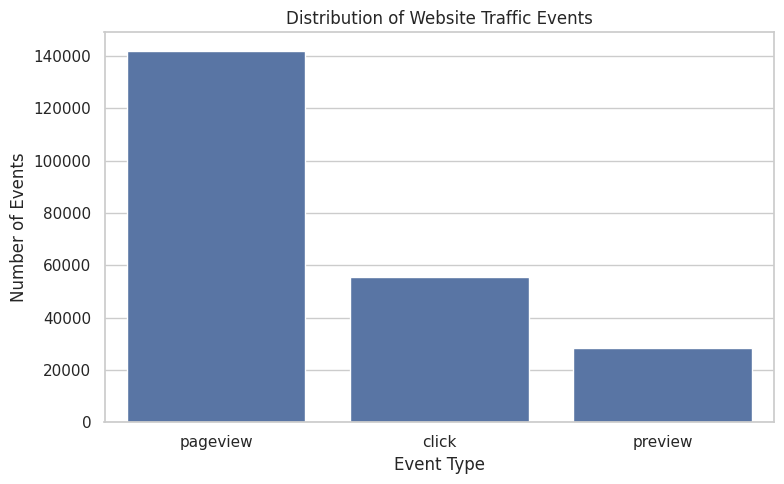

In [13]:
event_counts = df_clean['event'].value_counts()

plt.figure(figsize=(8, 5))
sns.barplot(
    x=event_counts.index,
    y=event_counts.values
)

plt.title('Distribution of Website Traffic Events')
plt.xlabel('Event Type')
plt.ylabel('Number of Events')
plt.tight_layout()
plt.show()

## Daily Traffic Trend Analysis

### Objective
To examine daily changes in recorded website traffic events and identify variations in user activity across the observation period.

### Approach
The event records are grouped by date and event type. Daily Pageviews, Clicks, and Previews are compared using a time-series visualization.

### Analytical Focus
- Identify the day with the highest recorded event activity.
- Compare daily patterns across the three event categories.
- Observe whether traffic activity remained consistent or fluctuated during the period.

**Note:** The analysis represents recorded event volumes, not unique users or website sessions.

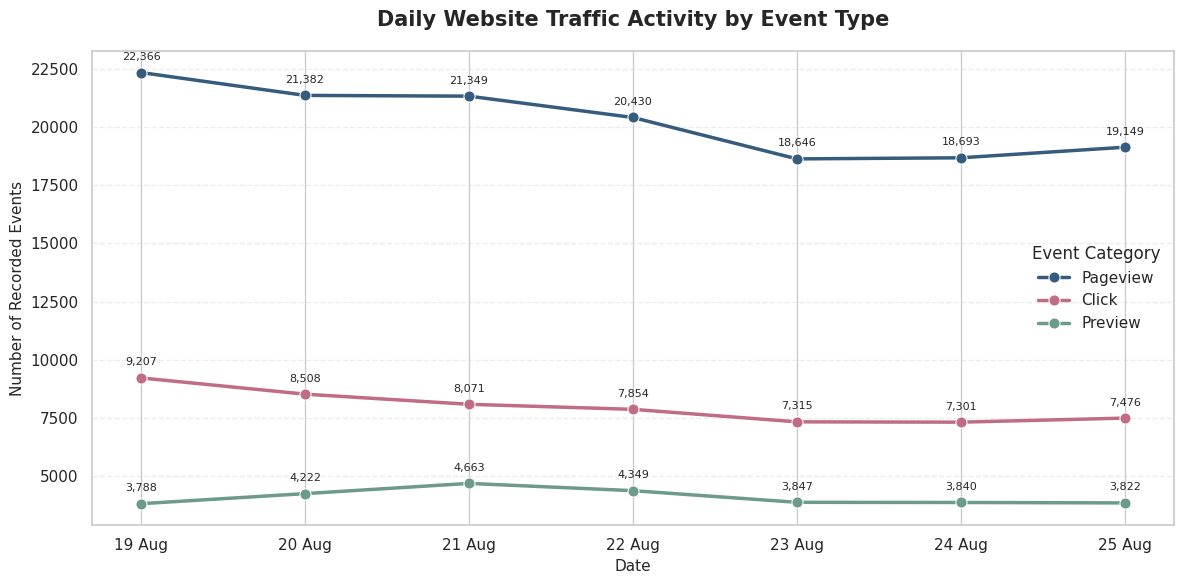

Daily Event Summary:


event,pageview,click,preview
date,,,
2021-08-19,22366,9207,3788
2021-08-20,21382,8508,4222
2021-08-21,21349,8071,4663
2021-08-22,20430,7854,4349
2021-08-23,18646,7315,3847
2021-08-24,18693,7301,3840
2021-08-25,19149,7476,3822


In [14]:
# Daily Traffic Trend Analysis

daily_events = (
    df_clean.groupby(['date', 'event'])
    .size()
    .unstack(fill_value=0)
    .sort_index()
)

event_order = ['pageview', 'click', 'preview']
daily_events = daily_events[event_order]

plt.figure(figsize=(12, 6))

colors = ['#355C7D', '#C06C84', '#6C9A8B']

for event, color in zip(event_order, colors):
    sns.lineplot(
        x=daily_events.index,
        y=daily_events[event],
        marker='o',
        markersize=8,
        linewidth=2.5,
        label=event.capitalize(),
        color=color
    )

    for date, value in zip(daily_events.index, daily_events[event]):
        plt.annotate(
            f'{value:,}',
            (date, value),
            textcoords="offset points",
            xytext=(0, 9),
            ha='center',
            fontsize=8
        )

plt.title(
    'Daily Website Traffic Activity by Event Type',
    fontsize=15,
    fontweight='bold',
    pad=18
)
plt.xlabel('Date', fontsize=11)
plt.ylabel('Number of Recorded Events', fontsize=11)
plt.xticks(daily_events.index,
           [d.strftime('%d %b') for d in daily_events.index],
           rotation=0)
plt.legend(title='Event Category', frameon=False)
plt.grid(axis='y', linestyle='--', alpha=0.35)
plt.tight_layout()
plt.show()

print("Daily Event Summary:")
display(daily_events)

### Key Findings and Interpretation

1. Pageviews recorded the highest activity on 19 August, with 22,366 events. The lowest activity was observed on 23 August, with 18,646 events.
2. Click activity followed a similar pattern, declining from 9,207 events on 19 August to 7,301 on 24 August.
3. Preview activity reached its peak on 21 August, recording 4,663 events.
4. Pageviews and clicks showed a gradual decline during the first five to six days, followed by a slight recovery towards the end of the observation period.
5. The different peak dates across event categories indicate that recorded content interactions did not follow exactly the same daily pattern.

**Conclusion:** The dataset shows variations in recorded traffic activity across the seven-day observation period. Pageviews consistently contributed the largest event volume, while preview activity followed a different daily pattern.

**Limitation:** These observations describe event counts only. The dataset does not contain sufficient information to determine changes in unique visitors, sessions, or individual user behaviour.

## Geographic Traffic Analysis

### Objective
To examine the geographical distribution of recorded traffic events and identify the countries contributing the highest event activity.

### Analytical Approach
The dataset is grouped by country to calculate the total number of recorded events. The ten countries with the highest event volumes are selected for comparative analysis.

### Key Questions
- Which countries contribute the highest recorded event activity?
- How concentrated is traffic among the leading countries?
- What is the geographical distribution of recorded interactions?

**Note:** Country-level event counts do not represent unique visitors or users. Records with an unknown country are excluded from the country ranking.

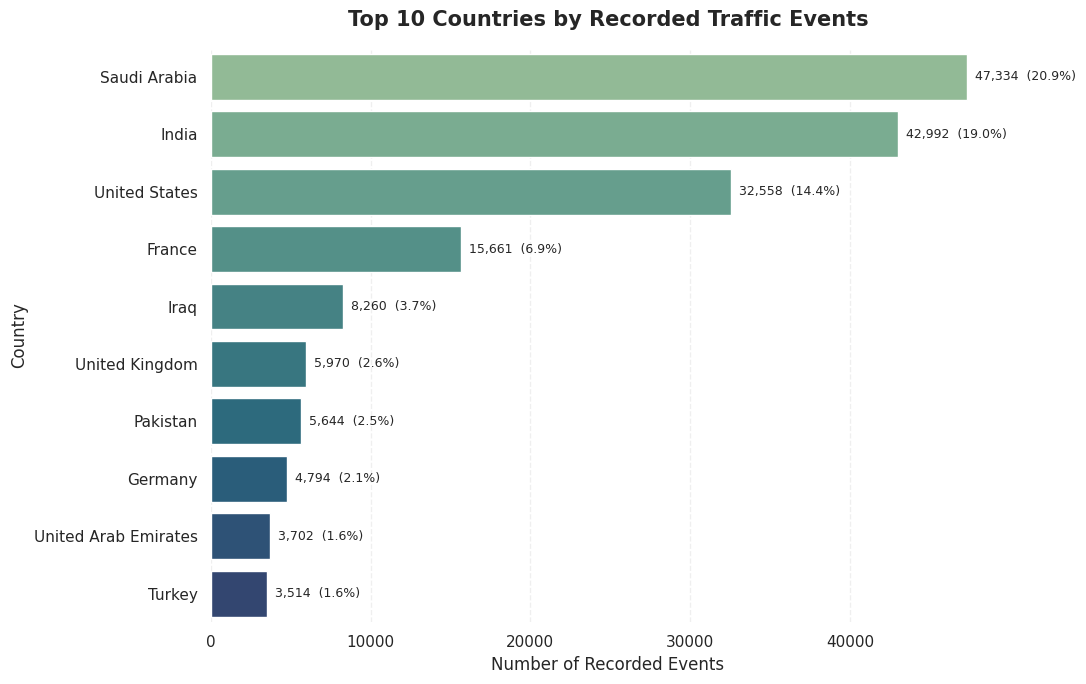

Top 10 Countries - Traffic Summary


,Recorded_Events,Share_of_Known_Country_Events (%)
country,,
Saudi Arabia,47334,20.92
India,42992,19.00
United States,32558,14.39
France,15661,6.92
Iraq,8260,3.65
United Kingdom,5970,2.64
Pakistan,5644,2.49
Germany,4794,2.12
United Arab Emirates,3702,1.64


In [15]:
# Geographic Traffic Analysis: Top 10 Countries

country_traffic = (
    df_clean[df_clean['country'] != 'Unknown']
    .groupby('country')
    .size()
    .sort_values(ascending=False)
)

top_10_countries = country_traffic.head(10)

country_share = (
    top_10_countries / country_traffic.sum() * 100
)

plt.figure(figsize=(11, 7))

ax = sns.barplot(
    x=top_10_countries.values,
    y=top_10_countries.index,
    hue=top_10_countries.index,
    palette='crest',
    legend=False
)

for index, (value, share) in enumerate(
    zip(top_10_countries.values, country_share.values)
):
    ax.text(
        value + 500,
        index,
        f'{value:,}  ({share:.1f}%)',
        va='center',
        fontsize=9
    )

plt.title(
    'Top 10 Countries by Recorded Traffic Events',
    fontsize=15,
    fontweight='bold',
    pad=16
)
plt.xlabel('Number of Recorded Events')
plt.ylabel('Country')
plt.grid(axis='x', linestyle='--', alpha=0.3)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

print("Top 10 Countries - Traffic Summary")
display(
    pd.DataFrame({
        'Recorded_Events': top_10_countries,
        'Share_of_Known_Country_Events (%)': country_share.round(2)
    })
)

### Key Findings and Interpretation

1. Saudi Arabia recorded the highest traffic activity, with 47,334 events, representing 20.92% of events with a known country.
2. India ranked second with 42,992 events (19.00%), followed by the United States with 32,558 events (14.39%).
3. The top three countries collectively contributed approximately 54.31% of known-country events.
4. France ranked fourth with 15,661 events, showing a considerable difference from the United States.
5. The top ten countries accounted for approximately 77.28% of all events with a known country.

**Conclusion:** Recorded event activity was concentrated in a relatively small group of countries, with Saudi Arabia, India, and the United States emerging as the leading geographical contributors.

**Limitation:** These figures represent recorded events, not unique visitors or users. Multiple events may originate from the same user or location.

## City-Level Traffic Analysis

### Objective
To identify the cities contributing the highest number of recorded traffic events and examine the distribution of activity across geographical locations.

### Analytical Approach
Traffic events are grouped by city. Records with missing city information, represented by the "Unknown" label, are excluded from the ranking. The ten cities with the highest recorded event counts are visualized.

### Key Questions
- Which cities have the highest recorded event activity?
- How is event activity distributed among the leading cities?
- Do a small number of cities account for a substantial share of recorded events?

**Note:** City-level event counts do not represent unique visitors or sessions. The dataset may contain multiple events from the same user or location.

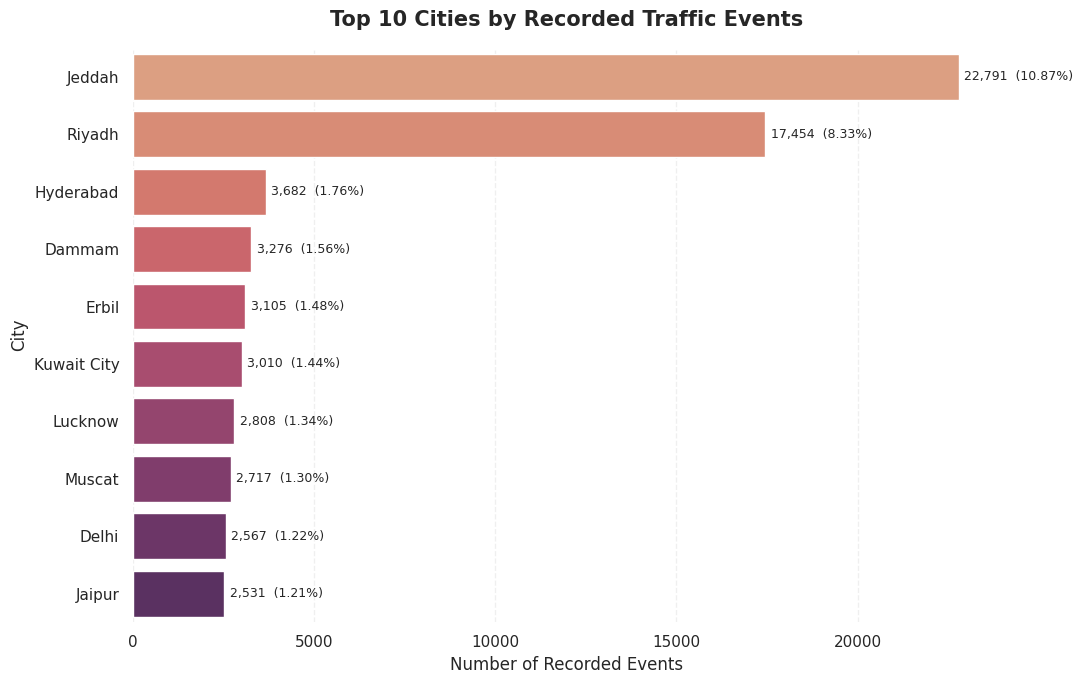

Top 10 Cities - Traffic Summary


,Recorded_Events,Share_of_Known_City_Events (%)
city,,
Jeddah,22791,10.87
Riyadh,17454,8.33
Hyderabad,3682,1.76
Dammam,3276,1.56
Erbil,3105,1.48
Kuwait City,3010,1.44
Lucknow,2808,1.34
Muscat,2717,1.30
Delhi,2567,1.22


In [16]:
# City-Level Traffic Analysis: Top 10 Cities

city_traffic = (
    df_clean[df_clean['city'] != 'Unknown']
    .groupby('city')
    .size()
    .sort_values(ascending=False)
)

top_10_cities = city_traffic.head(10)

city_share = (
    top_10_cities / city_traffic.sum() * 100
)

plt.figure(figsize=(11, 7))

ax = sns.barplot(
    x=top_10_cities.values,
    y=top_10_cities.index,
    hue=top_10_cities.index,
    palette='flare',
    legend=False
)

for index, (value, share) in enumerate(
    zip(top_10_cities.values, city_share.values)
):
    ax.text(
        value + 150,
        index,
        f'{value:,}  ({share:.2f}%)',
        va='center',
        fontsize=9
    )

plt.title(
    'Top 10 Cities by Recorded Traffic Events',
    fontsize=15,
    fontweight='bold',
    pad=16
)
plt.xlabel('Number of Recorded Events')
plt.ylabel('City')
plt.grid(axis='x', linestyle='--', alpha=0.3)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

print("Top 10 Cities - Traffic Summary")
display(
    pd.DataFrame({
        'Recorded_Events': top_10_cities,
        'Share_of_Known_City_Events (%)': city_share.round(2)
    })
)

### Key Findings and Interpretation

1. Jeddah recorded the highest event activity, with 22,791 events, representing 10.87% of events with a known city.
2. Riyadh ranked second with 17,454 events (8.33%).
3. Jeddah and Riyadh together contributed approximately 19.20% of known-city events.
4. A substantial difference exists between the second-ranked city, Riyadh, and the third-ranked city, Hyderabad.
5. Four Indian cities—Hyderabad, Lucknow, Delhi, and Jaipur—feature among the ten leading cities.

**Conclusion:** Recorded city-level activity is concentrated in Jeddah and Riyadh, while several other cities contribute comparatively smaller event volumes.

**Limitation:** These counts represent recorded events, not distinct visitors. The dataset does not provide sufficient information to identify unique individuals or their actual locations.

## Content Performance Analysis

### Artist-Level Engagement

### Objective
To identify artists receiving the highest recorded event activity and understand how interactions are distributed across available music content.

### Analytical Approach
Events are grouped by artist to calculate the total recorded activity associated with each artist. Records labelled as "Unknown" are excluded from the ranking.

### Key Questions
- Which artists have the highest recorded event volumes?
- How concentrated is event activity among the leading artists?
- Which artists appear most frequently in the available event data?

**Note:** Artist-level event counts represent recorded interactions across clicks, pageviews, and previews. They do not represent unique listeners, streams, or users.

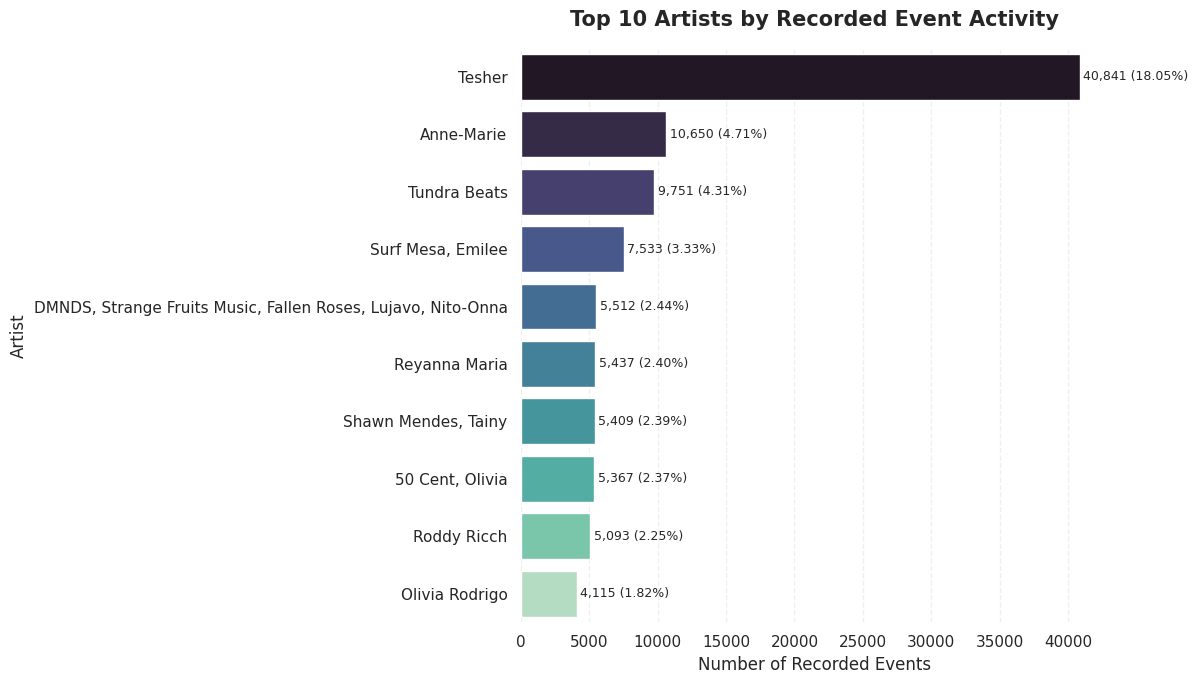

Top 10 Artists - Performance Summary


,Recorded_Events,Share_of_Known_Artist_Events (%)
artist,,
Tesher,40841,18.05
Anne-Marie,10650,4.71
Tundra Beats,9751,4.31
"Surf Mesa, Emilee",7533,3.33
"DMNDS, Strange Fruits Music, Fallen Roses, Lujavo, Nito-Onna",5512,2.44
Reyanna Maria,5437,2.40
"Shawn Mendes, Tainy",5409,2.39
"50 Cent, Olivia",5367,2.37
Roddy Ricch,5093,2.25


In [17]:
# Artist-Level Content Performance

artist_traffic = (
    df_clean[df_clean['artist'] != 'Unknown']
    .groupby('artist')
    .size()
    .sort_values(ascending=False)
)

top_10_artists = artist_traffic.head(10)

artist_share = (
    top_10_artists / artist_traffic.sum() * 100
)

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    x=top_10_artists.values,
    y=top_10_artists.index,
    hue=top_10_artists.index,
    palette='mako',
    legend=False
)

for index, (value, share) in enumerate(
    zip(top_10_artists.values, artist_share.values)
):
    ax.text(
        value + 250,
        index,
        f'{value:,} ({share:.2f}%)',
        va='center',
        fontsize=9
    )

plt.title(
    'Top 10 Artists by Recorded Event Activity',
    fontsize=15,
    fontweight='bold',
    pad=16
)
plt.xlabel('Number of Recorded Events')
plt.ylabel('Artist')
plt.grid(axis='x', linestyle='--', alpha=0.3)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

print("Top 10 Artists - Performance Summary")
display(
    pd.DataFrame({
        'Recorded_Events': top_10_artists,
        'Share_of_Known_Artist_Events (%)': artist_share.round(2)
    })
)

### Key Findings and Interpretation

1. Tesher recorded the highest event activity, with 40,841 events, accounting for 18.05% of known-artist events.
2. Anne-Marie ranked second with 10,650 events (4.71%), followed by Tundra Beats with 9,751 events (4.31%).
3. Tesher's recorded event volume was approximately 3.83 times higher than that of Anne-Marie.
4. The top three artists collectively contributed approximately 27.07% of known-artist events.
5. The remaining artists in the top ten showed relatively closer event volumes compared with the leading artist.

**Conclusion:** Recorded content activity was strongly concentrated around Tesher, while the other leading artists had comparatively lower event volumes.

**Limitation:** These figures combine pageviews, clicks, and previews. They should not be interpreted as unique listeners, streams, or individual user engagement.

## Album-Level Performance Analysis

### Objective
To identify the albums associated with the highest recorded event activity and examine the distribution of interactions across available album content.

### Analytical Approach
The dataset is grouped by album to calculate total recorded events. Records labelled as "Unknown" are excluded from the ranking, and the ten most active albums are visualized.

### Key Questions
- Which albums have the highest recorded event activity?
- How concentrated is activity among the leading albums?
- Which albums appear most frequently in the event records?

**Note:** Album-level event counts represent recorded interactions, not album sales, streams, or unique listeners.

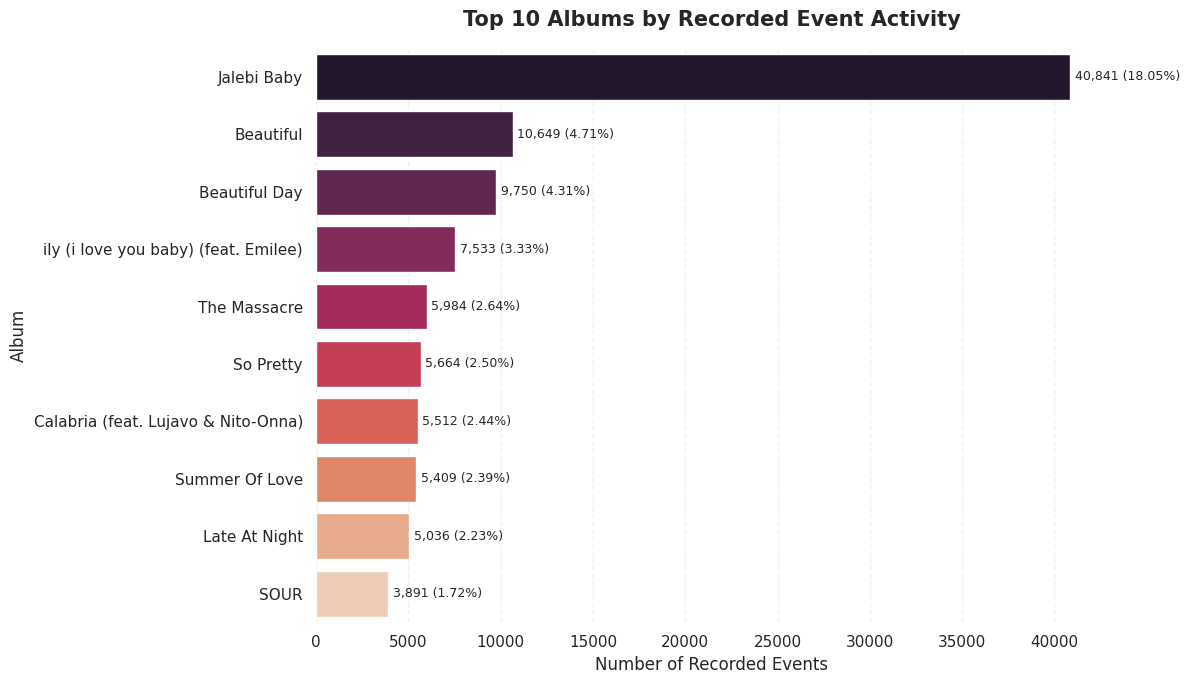

Top 10 Albums - Performance Summary


,Recorded_Events,Share_of_Known_Album_Events (%)
album,,
Jalebi Baby,40841,18.05
Beautiful,10649,4.71
Beautiful Day,9750,4.31
ily (i love you baby) (feat. Emilee),7533,3.33
The Massacre,5984,2.64
So Pretty,5664,2.50
Calabria (feat. Lujavo & Nito-Onna),5512,2.44
Summer Of Love,5409,2.39
Late At Night,5036,2.23


In [18]:
# Album-Level Content Performance

album_traffic = (
    df_clean[df_clean['album'] != 'Unknown']
    .groupby('album')
    .size()
    .sort_values(ascending=False)
)

top_10_albums = album_traffic.head(10)

album_share = (
    top_10_albums / album_traffic.sum() * 100
)

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    x=top_10_albums.values,
    y=top_10_albums.index,
    hue=top_10_albums.index,
    palette='rocket',
    legend=False
)

for index, (value, share) in enumerate(
    zip(top_10_albums.values, album_share.values)
):
    ax.text(
        value + 250,
        index,
        f'{value:,} ({share:.2f}%)',
        va='center',
        fontsize=9
    )

plt.title(
    'Top 10 Albums by Recorded Event Activity',
    fontsize=15,
    fontweight='bold',
    pad=16
)
plt.xlabel('Number of Recorded Events')
plt.ylabel('Album')
plt.grid(axis='x', linestyle='--', alpha=0.3)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

print("Top 10 Albums - Performance Summary")
display(
    pd.DataFrame({
        'Recorded_Events': top_10_albums,
        'Share_of_Known_Album_Events (%)': album_share.round(2)
    })
)

### Key Findings and Interpretation

1. Jalebi Baby recorded the highest event activity, with 40,841 events, representing 18.05% of known-album events.
2. Beautiful ranked second with 10,649 events (4.71%), followed by Beautiful Day with 9,750 events (4.31%).
3. Jalebi Baby recorded approximately 3.83 times the event volume of the second-ranked album.
4. The top three albums collectively contributed approximately 27.07% of known-album events.
5. The remaining albums showed relatively closer event volumes compared with Jalebi Baby.

**Conclusion:** Recorded album-level activity was strongly concentrated around Jalebi Baby, while the other leading albums contributed smaller event volumes.

**Limitation:** These figures represent recorded pageviews, clicks, and previews. They should not be interpreted as album sales, streams, or unique listeners.

## Track-Level Performance Analysis

### Objective
To identify the individual tracks associated with the highest recorded event activity.

### Analytical Approach
Event records are grouped by track. The top ten tracks are ranked according to their total recorded event counts. Unknown track entries are excluded.

### Key Questions
- Which tracks have the highest recorded event activity?
- How concentrated is activity among the leading tracks?
- Do the most active tracks show a similar pattern to the leading albums?

**Note:** Recorded track events do not represent unique listeners, music streams, or actual plays.

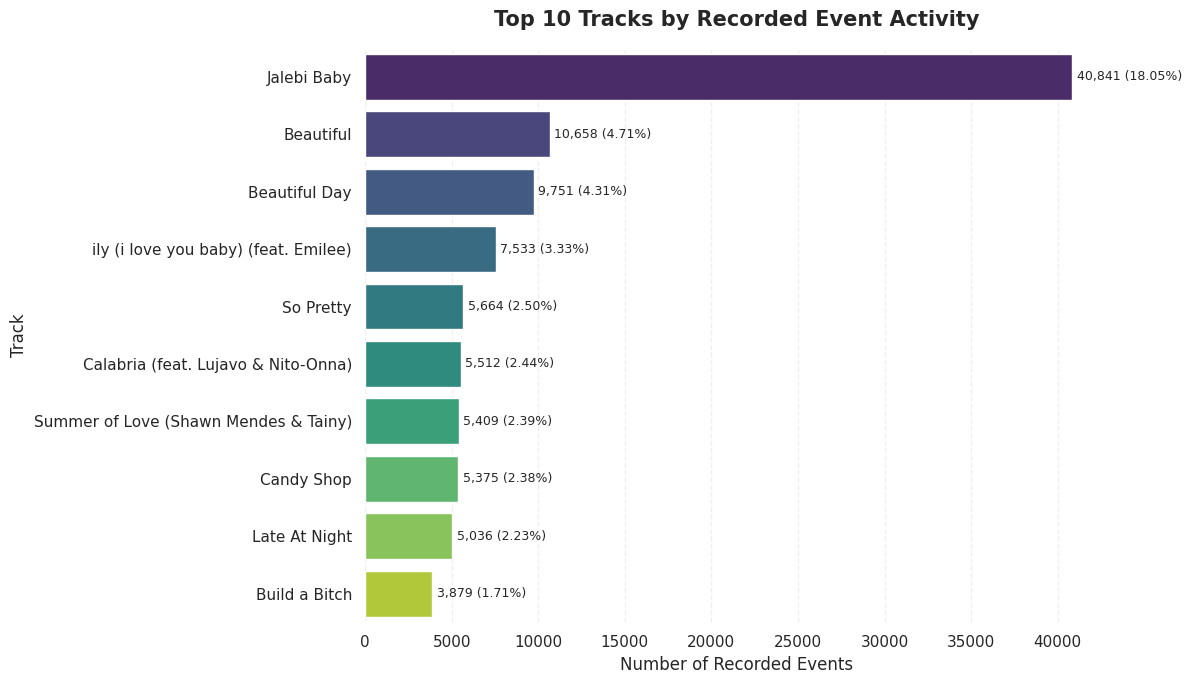

Top 10 Tracks - Performance Summary


,Recorded_Events,Share_of_Known_Track_Events (%)
track,,
Jalebi Baby,40841,18.05
Beautiful,10658,4.71
Beautiful Day,9751,4.31
ily (i love you baby) (feat. Emilee),7533,3.33
So Pretty,5664,2.50
Calabria (feat. Lujavo & Nito-Onna),5512,2.44
Summer of Love (Shawn Mendes & Tainy),5409,2.39
Candy Shop,5375,2.38
Late At Night,5036,2.23


In [19]:
# Track-Level Content Performance

track_traffic = (
    df_clean[df_clean['track'] != 'Unknown']
    .groupby('track')
    .size()
    .sort_values(ascending=False)
)

top_10_tracks = track_traffic.head(10)

track_share = (
    top_10_tracks / track_traffic.sum() * 100
)

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    x=top_10_tracks.values,
    y=top_10_tracks.index,
    hue=top_10_tracks.index,
    palette='viridis',
    legend=False
)

for index, (value, share) in enumerate(
    zip(top_10_tracks.values, track_share.values)
):
    ax.text(
        value + 250,
        index,
        f'{value:,} ({share:.2f}%)',
        va='center',
        fontsize=9
    )

plt.title(
    'Top 10 Tracks by Recorded Event Activity',
    fontsize=15,
    fontweight='bold',
    pad=16
)
plt.xlabel('Number of Recorded Events')
plt.ylabel('Track')
plt.grid(axis='x', linestyle='--', alpha=0.3)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

print("Top 10 Tracks - Performance Summary")
display(
    pd.DataFrame({
        'Recorded_Events': top_10_tracks,
        'Share_of_Known_Track_Events (%)': track_share.round(2)
    })
)

### Key Findings and Interpretation

1. Jalebi Baby recorded the highest track-level event activity, with 40,841 events, representing 18.05% of known-track events.
2. Beautiful ranked second with 10,658 events (4.71%), followed by Beautiful Day with 9,751 events (4.31%).
3. Jalebi Baby recorded approximately 3.83 times the event volume of the second-ranked track.
4. The top three tracks collectively contributed approximately 27.07% of known-track events.
5. Jalebi Baby consistently appeared among the leading entries in artist-level, album-level, and track-level analysis.

**Conclusion:** Recorded track-level activity was concentrated around Jalebi Baby, while the remaining leading tracks showed comparatively lower event volumes.

**Limitation:** These figures represent recorded pageviews, clicks, and previews. They do not measure unique listeners, actual music streams, or individual listening behaviour.

## Artist-Level Event Type Analysis

### Objective
To compare Pageviews, Clicks, and Previews across the leading artists and understand how different types of recorded interactions contribute to artist-level activity.

### Analytical Approach
The dataset is grouped by artist and event type. The ten artists with the highest overall event volumes are selected, and their event-category distributions are compared.

### Key Questions
- Which event category contributes most to each leading artist?
- Do artists show similar or different event-type patterns?
- Which artists record comparatively higher click and preview activity?

**Note:** Event-category counts represent recorded interactions, not unique users, listening sessions, or conversion rates.

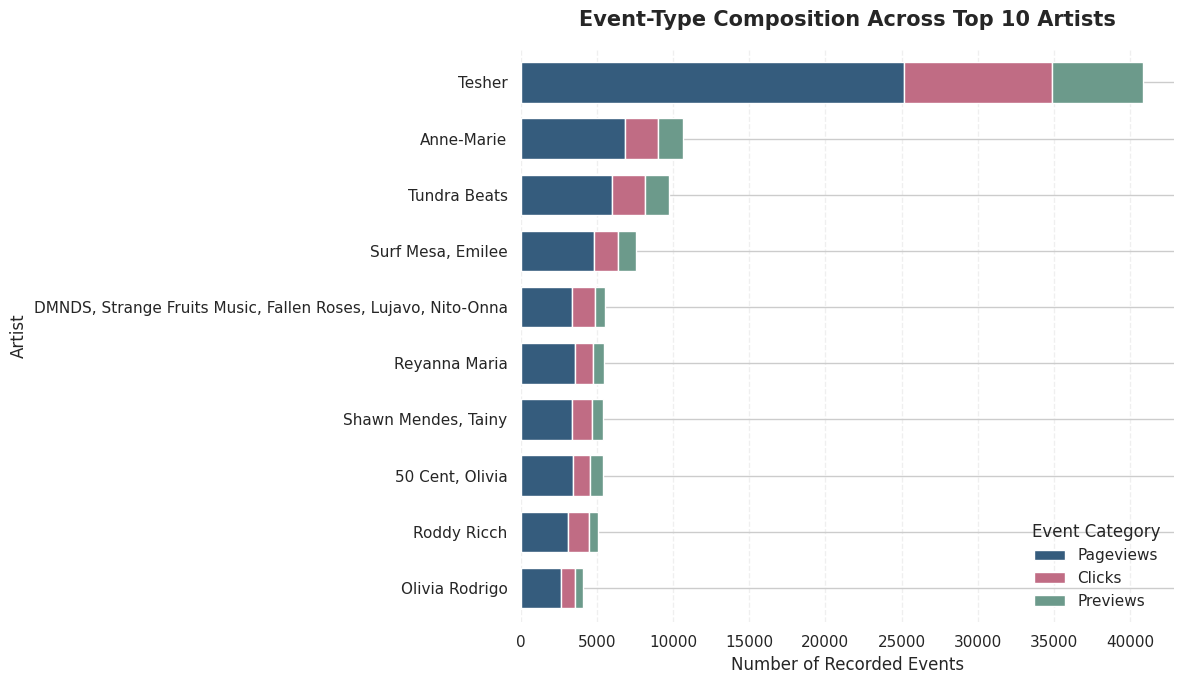

Artist-Level Event Type Summary:


,Pageviews,Clicks,Previews
artist,,,
Tesher,25175,9692,5974
Anne-Marie,6820,2172,1658
Tundra Beats,5982,2198,1571
"Surf Mesa, Emilee",4826,1589,1118
"DMNDS, Strange Fruits Music, Fallen Roses, Lujavo, Nito-Onna",3354,1500,658
Reyanna Maria,3532,1187,718
"Shawn Mendes, Tainy",3338,1359,712
"50 Cent, Olivia",3407,1111,849
Roddy Ricch,3071,1388,634


In [20]:
# Artist-Level Event Type Comparison

top_artist_names = top_10_artists.index

artist_event_data = (
    df_clean[df_clean['artist'].isin(top_artist_names)]
    .groupby(['artist', 'event'])
    .size()
    .unstack(fill_value=0)
)

artist_event_data = artist_event_data.reindex(
    index=top_artist_names,
    columns=['pageview', 'click', 'preview'],
    fill_value=0
)

artist_event_data.columns = ['Pageviews', 'Clicks', 'Previews']

ax = artist_event_data.plot(
    kind='barh',
    stacked=True,
    figsize=(12, 7),
    color=['#355C7D', '#C06C84', '#6C9A8B'],
    width=0.72
)

ax.set_title(
    'Event-Type Composition Across Top 10 Artists',
    fontsize=15,
    fontweight='bold',
    pad=16
)
ax.set_xlabel('Number of Recorded Events')
ax.set_ylabel('Artist')
ax.legend(title='Event Category', frameon=False)
ax.grid(axis='x', linestyle='--', alpha=0.3)
ax.invert_yaxis()

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

print("Artist-Level Event Type Summary:")
display(artist_event_data)

### Key Findings and Interpretation

1. Tesher recorded the highest activity across all three event categories, with 25,175 Pageviews, 9,692 Clicks, and 5,974 Previews.
2. Pageviews represented the largest event category for every artist in the top ten.
3. Tundra Beats recorded the second-highest number of Clicks, with 2,198 events.
4. DMNDS and collaborators recorded 1,500 Clicks, showing comparatively strong click activity relative to several artists with similar or higher total event volumes.
5. 50 Cent and Olivia recorded 849 Previews, the second-highest preview count among the selected artists.

**Conclusion:** Pageviews dominated recorded activity across the leading artists, while click and preview volumes varied between artists.

**Limitation:** These are event counts, not user-level engagement rates. The dataset does not identify unique users or sessions, so conversion or engagement rates cannot be calculated.

## Daily Event Composition Analysis

### Objective
To examine how Pageviews, Clicks, and Previews contribute to the total recorded event activity on each day.

### Analytical Approach
Daily event counts are converted into percentages of the respective day's total events. A 100% stacked bar chart is used to compare the composition of event categories across the observation period.

### Key Questions
- Which event category contributes the largest share each day?
- Does the proportion of Clicks and Previews change over time?
- Is the daily event composition relatively stable or variable?

**Note:** Percentages represent the composition of recorded events, not user engagement or conversion rates.

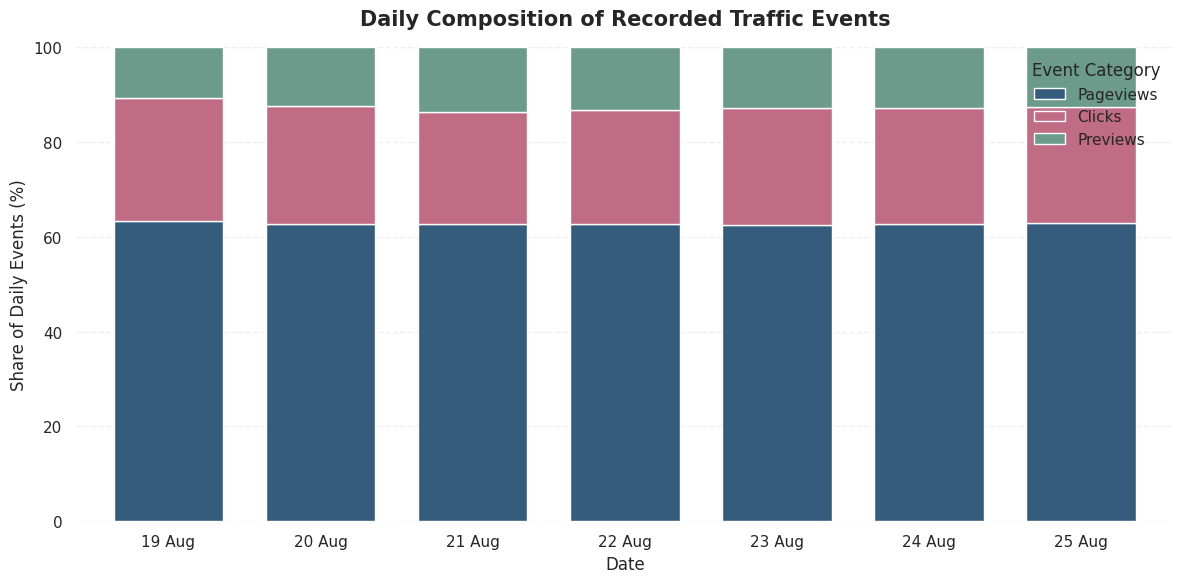

Daily Event Composition (%):


,Pageviews,Clicks,Previews
date,,,
2021-08-19,63.25,26.04,10.71
2021-08-20,62.68,24.94,12.38
2021-08-21,62.64,23.68,13.68
2021-08-22,62.61,24.07,13.33
2021-08-23,62.55,24.54,12.91
2021-08-24,62.66,24.47,12.87
2021-08-25,62.89,24.55,12.55


In [21]:
# Daily Event Composition Analysis

daily_event_mix = (
    daily_events
    .div(daily_events.sum(axis=1), axis=0)
    * 100
)

daily_event_mix = daily_event_mix[
    ['pageview', 'click', 'preview']
]

daily_event_mix.columns = [
    'Pageviews', 'Clicks', 'Previews'
]

ax = daily_event_mix.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6),
    color=['#355C7D', '#C06C84', '#6C9A8B'],
    width=0.72
)

ax.set_title(
    'Daily Composition of Recorded Traffic Events',
    fontsize=15,
    fontweight='bold',
    pad=16
)
ax.set_xlabel('Date')
ax.set_ylabel('Share of Daily Events (%)')
ax.set_xticklabels(
    [date.strftime('%d %b') for date in daily_event_mix.index],
    rotation=0
)
ax.set_ylim(0, 100)
ax.legend(title='Event Category', frameon=False, loc='upper right')
ax.grid(axis='y', linestyle='--', alpha=0.3)

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

print("Daily Event Composition (%):")
display(daily_event_mix.round(2))

### Key Findings and Interpretation

1. Pageviews consistently contributed the largest share of daily events, ranging from 62.55% to 63.25%.
2. Clicks accounted for approximately 23.68% to 26.04% of daily event activity.
3. Preview activity reached its highest proportion on 21 August, at 13.68%.
4. The preview share increased from 10.71% on 19 August to 13.68% on 21 August, followed by a gradual decline.
5. The overall distribution of Pageviews, Clicks, and Previews remained relatively stable throughout the seven-day observation period.

**Conclusion:** Although the total number of recorded events varied by date, the relative contribution of the three event categories remained broadly consistent.

**Limitation:** Event composition percentages describe the distribution of recorded events. They do not represent user engagement rates, click-through rates, or conversion rates.

## Link-Level Performance Analysis

### Objective
To identify the links associated with the highest recorded event activity and examine the distribution of interactions across available link identifiers.

### Analytical Approach
The dataset is grouped by link ID to calculate the total number of recorded events. The ten most active link IDs are selected for comparative analysis.

### Key Questions
- Which link IDs have the highest recorded event volumes?
- How concentrated is activity among the leading links?
- Which event categories contribute to the activity of the leading links?

**Note:** Link IDs are identifiers, not website page URLs. Their event counts do not represent unique visitors, sessions, or conversion rates.

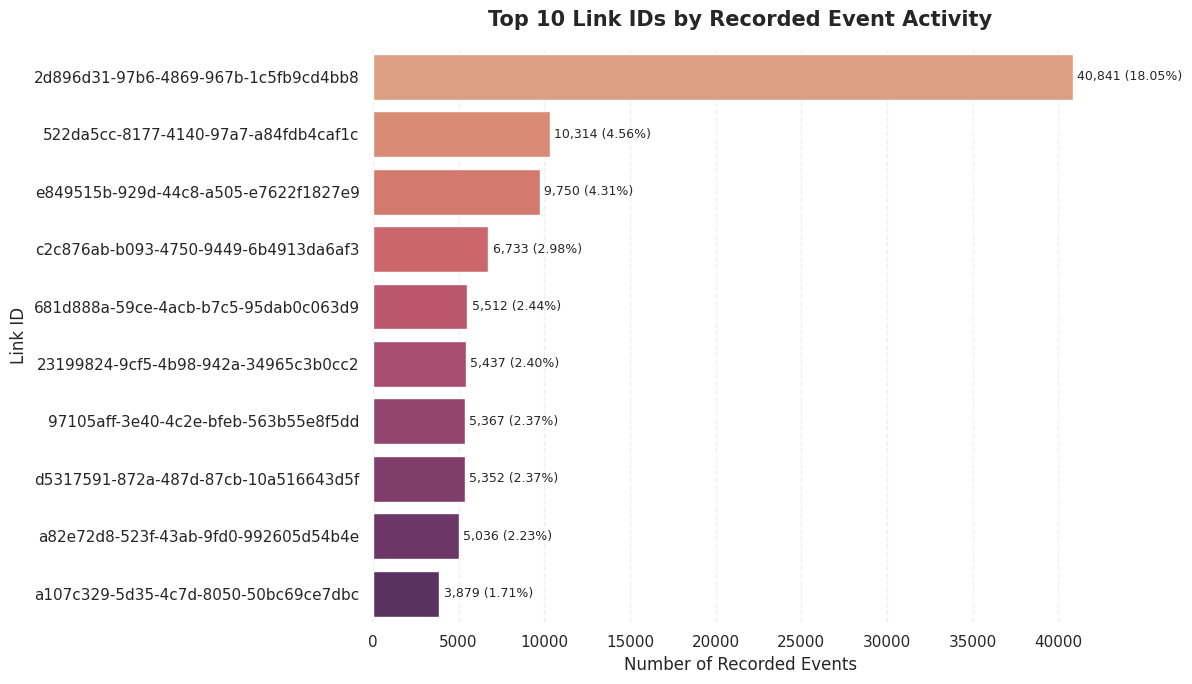

Top 10 Links - Performance Summary


,Recorded_Events,Share_of_Total_Events (%)
linkid,,
2d896d31-97b6-4869-967b-1c5fb9cd4bb8,40841,18.05
522da5cc-8177-4140-97a7-a84fdb4caf1c,10314,4.56
e849515b-929d-44c8-a505-e7622f1827e9,9750,4.31
c2c876ab-b093-4750-9449-6b4913da6af3,6733,2.98
681d888a-59ce-4acb-b7c5-95dab0c063d9,5512,2.44
23199824-9cf5-4b98-942a-34965c3b0cc2,5437,2.40
97105aff-3e40-4c2e-bfeb-563b55e8f5dd,5367,2.37
d5317591-872a-487d-87cb-10a516643d5f,5352,2.37
a82e72d8-523f-43ab-9fd0-992605d54b4e,5036,2.23


In [22]:
# Link-Level Performance Analysis

link_traffic = (
    df_clean.groupby('linkid')
    .size()
    .sort_values(ascending=False)
)

top_10_links = link_traffic.head(10)

link_share = (
    top_10_links / link_traffic.sum() * 100
)

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    x=top_10_links.values,
    y=top_10_links.index,
    hue=top_10_links.index,
    palette='flare',
    legend=False
)

for index, (value, share) in enumerate(
    zip(top_10_links.values, link_share.values)
):
    ax.text(
        value + 250,
        index,
        f'{value:,} ({share:.2f}%)',
        va='center',
        fontsize=9
    )

plt.title(
    'Top 10 Link IDs by Recorded Event Activity',
    fontsize=15,
    fontweight='bold',
    pad=16
)
plt.xlabel('Number of Recorded Events')
plt.ylabel('Link ID')
plt.grid(axis='x', linestyle='--', alpha=0.3)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

print("Top 10 Links - Performance Summary")
display(
    pd.DataFrame({
        'Recorded_Events': top_10_links,
        'Share_of_Total_Events (%)': link_share.round(2)
    })
)

### Key Findings and Interpretation

1. The leading link ID (2d896d31-97b6-4869-967b-1c5fb0c063d9) recorded 40,841 events, representing 18.05% of total recorded activity.
2. The second-ranked link recorded 10,314 events (4.56%), followed by the third-ranked link with 9,750 events (4.31%).
3. The leading link generated approximately 3.96 times the event volume of the second-ranked link.
4. The top three links collectively accounted for approximately 26.92% of total recorded events.
5. The ten leading links contributed approximately 43.42% of all recorded events.

**Conclusion:** Recorded event activity was concentrated among a relatively small group of link identifiers, with the leading link showing a substantial difference from the remaining links.

**Limitation:** The dataset provides link IDs rather than actual page URLs or landing-page information. Therefore, the specific content or destination associated with each link cannot be identified from these results alone.

## Event-Type Analysis Across Top Links

### Objective
To compare Pageviews, Clicks, and Previews across the ten most active link identifiers.

### Analytical Approach
The dataset is filtered to include the top ten link IDs and grouped by link ID and event category. A stacked horizontal bar chart is used to compare the event composition of each link.

### Key Questions
- Which event category dominates each leading link?
- Do the top links show similar event distributions?
- Which links record comparatively higher click and preview volumes?

**Note:** Link-level event counts represent recorded interactions. They do not establish unique visitors, sessions, or conversion rates.

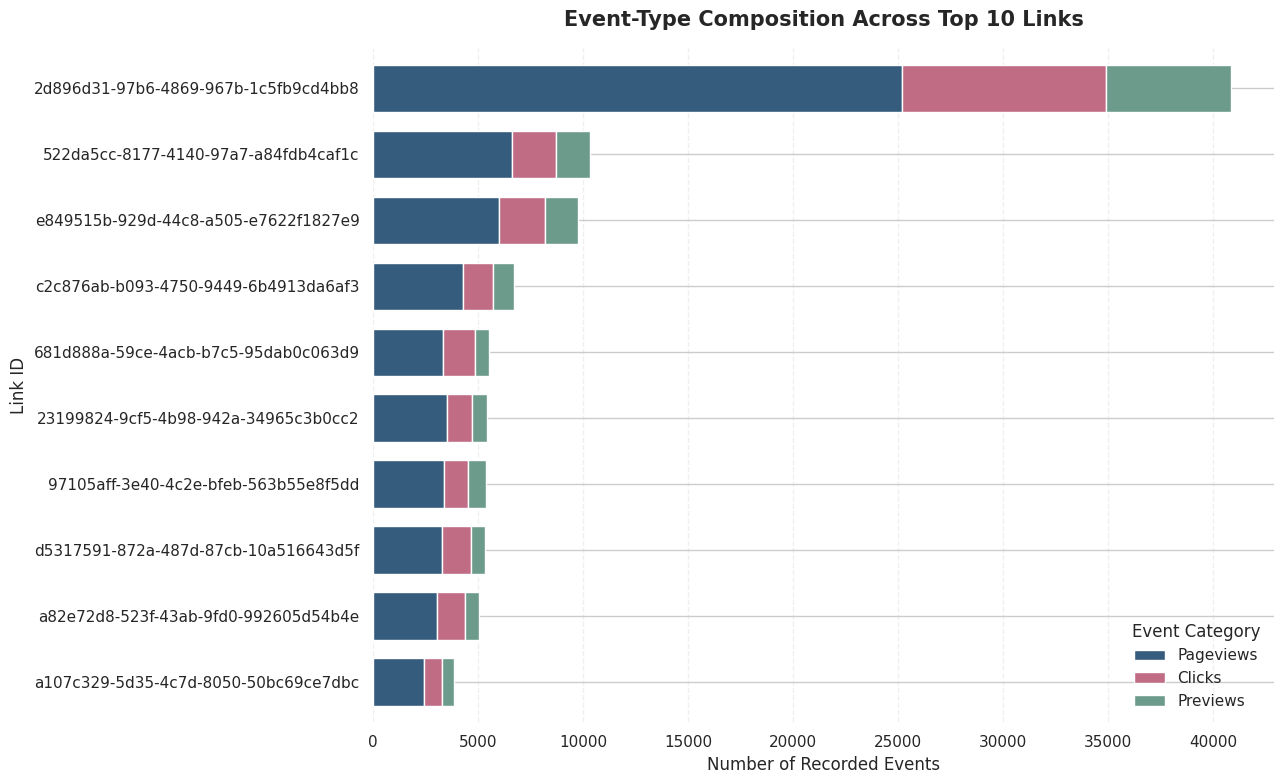

Link-Level Event Category Summary:


,Pageviews,Clicks,Previews
linkid,,,
2d896d31-97b6-4869-967b-1c5fb9cd4bb8,25175,9692,5974
522da5cc-8177-4140-97a7-a84fdb4caf1c,6600,2109,1605
e849515b-929d-44c8-a505-e7622f1827e9,5981,2198,1571
c2c876ab-b093-4750-9449-6b4913da6af3,4303,1429,1001
681d888a-59ce-4acb-b7c5-95dab0c063d9,3354,1500,658
23199824-9cf5-4b98-942a-34965c3b0cc2,3532,1187,718
97105aff-3e40-4c2e-bfeb-563b55e8f5dd,3407,1111,849
d5317591-872a-487d-87cb-10a516643d5f,3299,1353,700
a82e72d8-523f-43ab-9fd0-992605d54b4e,3039,1364,633


In [23]:
# Event-Type Distribution Across Top 10 Links

link_event_data = (
    df_clean[df_clean['linkid'].isin(top_10_links.index)]
    .groupby(['linkid', 'event'])
    .size()
    .unstack(fill_value=0)
)

link_event_data = link_event_data.reindex(
    index=top_10_links.index,
    columns=['pageview', 'click', 'preview'],
    fill_value=0
)

link_event_data.columns = ['Pageviews', 'Clicks', 'Previews']

ax = link_event_data.plot(
    kind='barh',
    stacked=True,
    figsize=(13, 8),
    color=['#355C7D', '#C06C84', '#6C9A8B'],
    width=0.72
)

ax.set_title(
    'Event-Type Composition Across Top 10 Links',
    fontsize=15,
    fontweight='bold',
    pad=16
)
ax.set_xlabel('Number of Recorded Events')
ax.set_ylabel('Link ID')
ax.legend(title='Event Category', frameon=False)
ax.grid(axis='x', linestyle='--', alpha=0.3)
ax.invert_yaxis()

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

print("Link-Level Event Category Summary:")
display(link_event_data)

### Key Findings and Interpretation

1. Pageviews are the highest recorded event category across all ten leading link IDs, followed by Clicks and Previews.
2. The first link ID (`2d896d31-97b6-4869-967b-1c5fb9cd4bb8`) records the highest activity, with 25,175 Pageviews, 9,692 Clicks, and 5,974 Previews.
3. The third link ID records the second-highest Pageviews (5,981) and Clicks (2,198) among the displayed links.
4. The fifth link ID records 1,500 Clicks, which is the second-highest click count in this group.
5. Although the overall event pattern is similar across the top links, the number of recorded interactions varies considerably between them.

**Conclusion:** The analysis shows that recorded activity is concentrated around a small group of link identifiers. Pageviews dominate the event volume across all ten links, while click and preview counts provide additional insight into how interactions are distributed.

**Limitation:** The dataset provides link IDs rather than actual page URLs and does not contain session or user identifiers. Therefore, this analysis cannot establish unique visitors, session-level engagement, or conversion rates for individual links.

## Event Interaction Rate Analysis

### Objective
To compare click and preview activity against pageview volume across the top ten link identifiers.

### Analytical Approach
Clicks and Previews are compared with Pageviews using event-level ratios. These metrics help examine how recorded interactions vary relative to pageview counts.

### Metrics
- Click-to-Pageview Ratio = (Clicks / Pageviews) × 100
- Preview-to-Pageview Ratio = (Previews / Pageviews) × 100

**Note:** These ratios are based on aggregated event counts. They should not be interpreted as actual conversion rates or the percentage of users who clicked or previewed a link, since unique user and session identifiers are unavailable.

In [24]:
link_interaction = link_event_data.copy()

link_interaction['Click-to-Pageview Ratio (%)'] = (
    link_interaction['Clicks'] / link_interaction['Pageviews'] * 100
)

link_interaction['Preview-to-Pageview Ratio (%)'] = (
    link_interaction['Previews'] / link_interaction['Pageviews'] * 100
)

link_interaction = link_interaction.sort_values(
    'Click-to-Pageview Ratio (%)',
    ascending=False
)

display(link_interaction.round(2))

,Pageviews,Clicks,Previews,Click-to-Pageview Ratio (%),Preview-to-Pageview Ratio (%)
linkid,,,,,
a82e72d8-523f-43ab-9fd0-992605d54b4e,3039,1364,633,44.88,20.83
681d888a-59ce-4acb-b7c5-95dab0c063d9,3354,1500,658,44.72,19.62
d5317591-872a-487d-87cb-10a516643d5f,3299,1353,700,41.01,21.22
2d896d31-97b6-4869-967b-1c5fb9cd4bb8,25175,9692,5974,38.50,23.73
e849515b-929d-44c8-a505-e7622f1827e9,5981,2198,1571,36.75,26.27
a107c329-5d35-4c7d-8050-50bc69ce7dbc,2440,827,612,33.89,25.08
23199824-9cf5-4b98-942a-34965c3b0cc2,3532,1187,718,33.61,20.33
c2c876ab-b093-4750-9449-6b4913da6af3,4303,1429,1001,33.21,23.26
97105aff-3e40-4c2e-bfeb-563b55e8f5dd,3407,1111,849,32.61,24.92


### Key Findings and Interpretation

1. The link ID `a82e72d8-523f-43ab-9fd0-992605d54b4e` recorded the highest Click-to-Pageview Ratio at 44.88%, closely followed by `681d888a-59ce-4acb-b7c5-95dab0c063d9` at 44.72%.
2. The link ID `e849515b-929d-44c8-a505-e7622f1827e9` recorded the highest Preview-to-Pageview Ratio at 26.27%.
3. The link ID `522da5cc-8177-4140-97a7-a84fdb4caf1c` had the lowest Click-to-Pageview Ratio at 31.95%.
4. The most active link by total event volume was `2d896d31-97b6-4869-967b-1c5fb9cd4bb8`, which also recorded 38.50% Click-to-Pageview and 23.73% Preview-to-Pageview ratios.
5. The results show that links with the highest total activity do not necessarily have the highest interaction ratios.

**Conclusion:** Comparing event-level ratios highlights differences in interaction patterns across link identifiers. Some links recorded relatively higher click activity compared with their pageview counts, while others showed higher preview activity.

**Limitation:** These ratios are calculated from aggregated event counts. They do not represent unique-user engagement or actual conversion rates because user and session identifiers are unavailable.

## Content Engagement Comparison

### Objective
To compare recorded engagement patterns across the ten most active artists.

### Analytical Approach
Artist-level event counts are used to calculate Click-to-Pageview and Preview-to-Pageview ratios. This comparison helps identify differences in recorded interactions across popular artists.

### Analytical Focus
- Compare click activity relative to pageviews.
- Compare preview activity relative to pageviews.
- Identify artists with comparatively higher interaction ratios.

**Note:** These are aggregated event-level ratios, not actual conversion rates or unique-user engagement metrics.

In [25]:
# Identify the top 10 artists by total recorded events
top_10_artist_names = (
    df_clean[df_clean['artist'] != 'Unknown']['artist']
    .value_counts()
    .head(10)
    .index
)

# Calculate event counts for the top 10 artists
artist_interaction = (
    df_clean[df_clean['artist'].isin(top_10_artist_names)]
    .groupby(['artist', 'event'])
    .size()
    .unstack(fill_value=0)
)

artist_interaction = artist_interaction.reindex(
    columns=['pageview', 'click', 'preview'],
    fill_value=0
)

artist_interaction.columns = ['Pageviews', 'Clicks', 'Previews']

# Calculate event-level interaction ratios
artist_interaction['Click-to-Pageview Ratio (%)'] = (
    artist_interaction['Clicks'] /
    artist_interaction['Pageviews'] * 100
)

artist_interaction['Preview-to-Pageview Ratio (%)'] = (
    artist_interaction['Previews'] /
    artist_interaction['Pageviews'] * 100
)

artist_interaction = artist_interaction.sort_values(
    'Click-to-Pageview Ratio (%)',
    ascending=False
)

display(artist_interaction.round(2))

,Pageviews,Clicks,Previews,Click-to-Pageview Ratio (%),Preview-to-Pageview Ratio (%)
artist,,,,,
Roddy Ricch,3071,1388,634,45.20,20.64
"DMNDS, Strange Fruits Music, Fallen Roses, Lujavo, Nito-Onna",3354,1500,658,44.72,19.62
"Shawn Mendes, Tainy",3338,1359,712,40.71,21.33
Tesher,25175,9692,5974,38.50,23.73
Tundra Beats,5982,2198,1571,36.74,26.26
Olivia Rodrigo,2668,926,521,34.71,19.53
Reyanna Maria,3532,1187,718,33.61,20.33
"Surf Mesa, Emilee",4826,1589,1118,32.93,23.17
"50 Cent, Olivia",3407,1111,849,32.61,24.92


### Key Findings and Interpretation

1. Roddy Ricch recorded the highest Click-to-Pageview Ratio at 45.20%, indicating the highest relative click-event volume among the ten artists analysed.
2. DMNDS and its collaborators recorded the second-highest Click-to-Pageview Ratio at 44.72%.
3. Tundra Beats achieved the highest Preview-to-Pageview Ratio at 26.26%, followed closely by Tesher at 23.73%.
4. Tesher recorded the highest overall event volume, with 25,175 Pageviews, 9,692 Clicks, and 5,974 Previews.
5. Anne-Marie recorded the lowest Click-to-Pageview Ratio at 31.85%, despite having the second-highest Pageview count.
6. These results show that the artist with the highest total activity is not necessarily the artist with the highest relative interaction ratios.

**Conclusion:** Artist-level comparison reveals different patterns of recorded engagement. Roddy Ricch leads in relative click activity, Tundra Beats leads in relative preview activity, and Tesher dominates in total recorded event volume.

**Limitation:** These ratios are based on aggregated event counts. They cannot establish individual listener behaviour, unique-user engagement, or actual conversion rates.

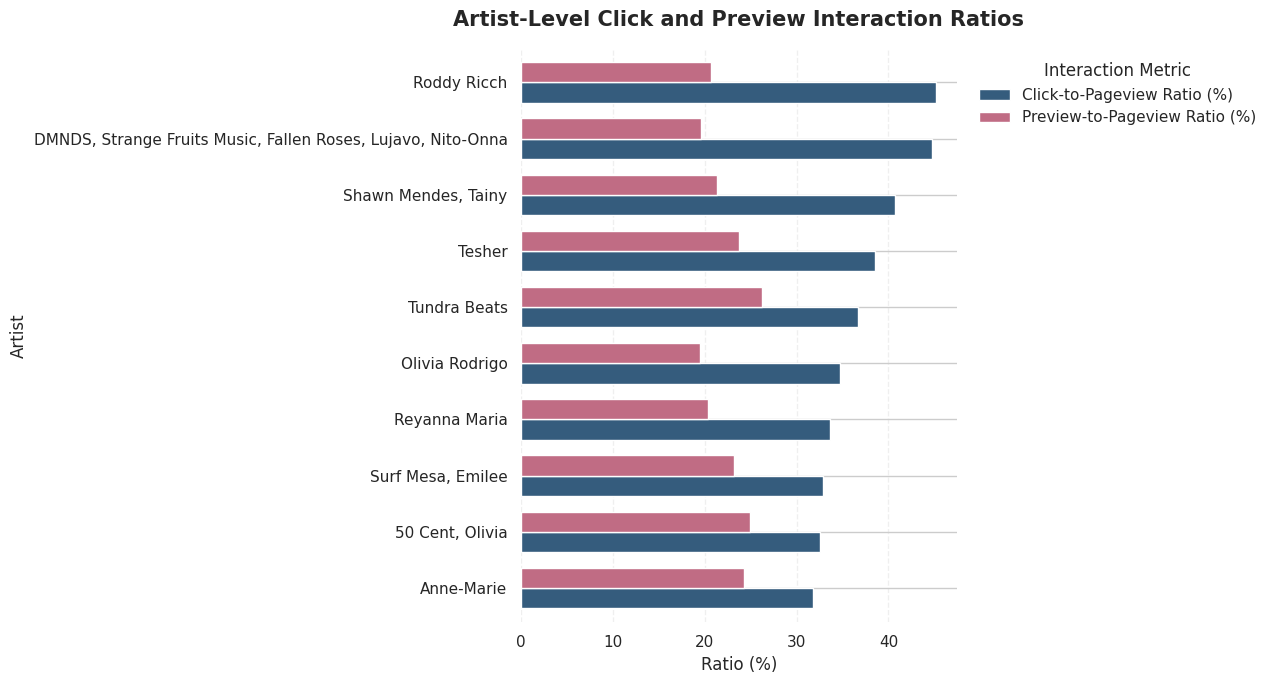

In [27]:
artist_ratios = artist_interaction[
    ['Click-to-Pageview Ratio (%)',
     'Preview-to-Pageview Ratio (%)']
].sort_values('Click-to-Pageview Ratio (%)')

fig, ax = plt.subplots(figsize=(13, 7))

artist_ratios.plot(
    kind='barh',
    ax=ax,
    width=0.72,
    color=['#355C7D', '#C06C84']
)

ax.set_title(
    'Artist-Level Click and Preview Interaction Ratios',
    fontsize=15,
    fontweight='bold',
    pad=16
)

ax.set_xlabel('Ratio (%)')
ax.set_ylabel('Artist')

ax.legend(
    title='Interaction Metric',
    loc='upper left',
    bbox_to_anchor=(1.02, 1),
    frameon=False
)

ax.grid(axis='x', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)

sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()

## Country-Level Event Engagement Analysis

### Objective
To compare the distribution of Pageviews, Clicks, and Previews across the leading countries in the dataset.

### Analytical Approach
The ten countries with the highest recorded event volumes are identified. Their event counts are grouped by event category and compared using a stacked horizontal bar chart.

### Analytical Focus
- Identify countries with the highest recorded activity.
- Compare Pageviews, Clicks, and Previews across countries.
- Examine differences in event composition across geographical markets.

**Note:** The analysis represents recorded event counts, not unique visitors or country-level conversion rates.

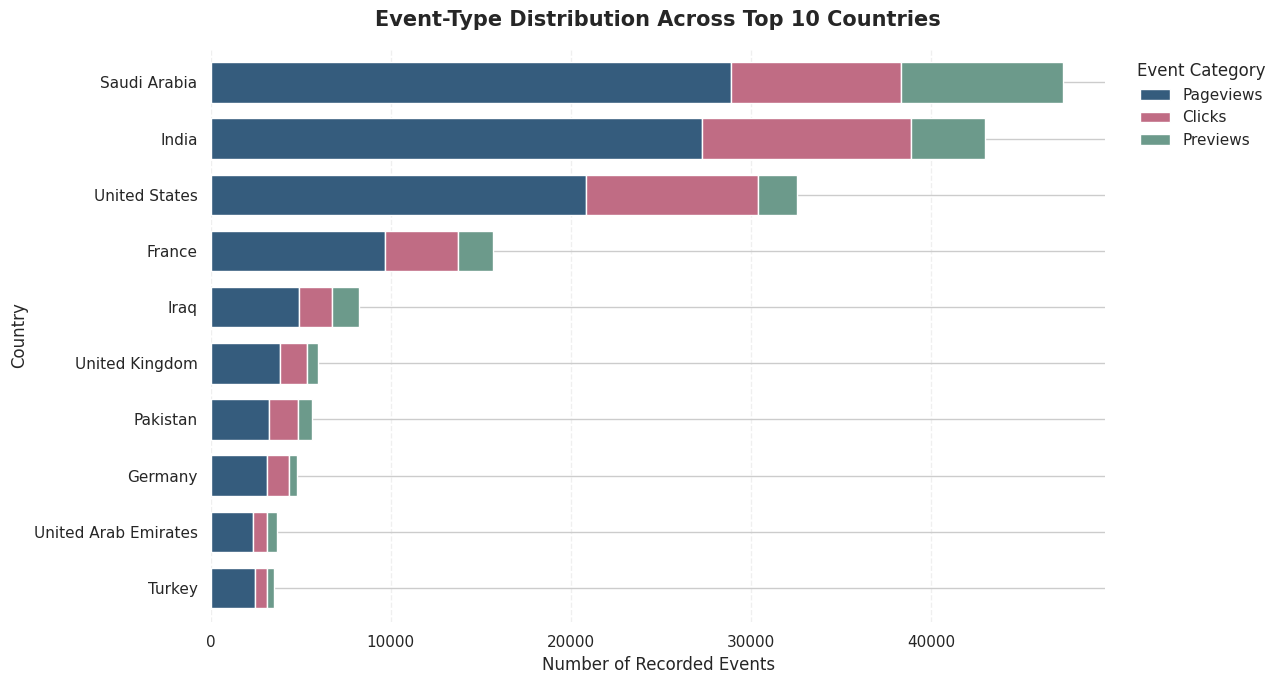

,Pageviews,Clicks,Previews,Total Events
country,,,,
Turkey,2462,654,398,3514
United Arab Emirates,2335,766,601,3702
Germany,3141,1225,428,4794
Pakistan,3212,1653,779,5644
United Kingdom,3845,1517,608,5970
Iraq,4897,1836,1527,8260
France,9674,4054,1933,15661
United States,20839,9533,2186,32558
India,27286,11609,4097,42992


In [28]:
top_10_countries = (
    df_clean[df_clean['country'] != 'Unknown']['country']
    .value_counts()
    .head(10)
    .index
)

country_event_data = (
    df_clean[df_clean['country'].isin(top_10_countries)]
    .groupby(['country', 'event'])
    .size()
    .unstack(fill_value=0)
)

country_event_data = country_event_data.reindex(
    columns=['pageview', 'click', 'preview'],
    fill_value=0
)

country_event_data.columns = ['Pageviews', 'Clicks', 'Previews']

country_event_data['Total Events'] = country_event_data.sum(axis=1)

country_event_data = country_event_data.sort_values(
    'Total Events',
    ascending=True
)

ax = country_event_data[
    ['Pageviews', 'Clicks', 'Previews']
].plot(
    kind='barh',
    stacked=True,
    figsize=(13, 7),
    width=0.72,
    color=['#355C7D', '#C06C84', '#6C9A8B']
)

ax.set_title(
    'Event-Type Distribution Across Top 10 Countries',
    fontsize=15,
    fontweight='bold',
    pad=16
)

ax.set_xlabel('Number of Recorded Events')
ax.set_ylabel('Country')
ax.legend(
    title='Event Category',
    loc='upper left',
    bbox_to_anchor=(1.02, 1),
    frameon=False
)

ax.grid(axis='x', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()

display(country_event_data)

### Key Findings and Interpretation

1. Saudi Arabia recorded the highest total event volume among the ten leading countries, with 47,334 events, followed by India with 42,992 events.
2. Saudi Arabia contributed the highest Pageview count (28,873) and Preview count (8,966) among the countries analysed.
3. India recorded the highest Click count at 11,609, indicating the largest volume of recorded click events in this comparison.
4. The United States ranked third in total recorded activity, with 32,558 events.
5. Pageviews represented the largest event category across all ten countries.
6. The differences in event counts across countries highlight the geographical variation in recorded traffic and interaction activity.

**Conclusion:** Saudi Arabia and India were the two largest contributors to recorded event activity. However, India led in click volume, while Saudi Arabia led in pageviews and previews.

**Limitation:** These figures represent recorded events rather than unique visitors. The dataset does not provide sufficient information to compare country-level sessions, individual user engagement, or actual conversion rates.

In [29]:
country_interaction = country_event_data[
    ['Pageviews', 'Clicks', 'Previews']
].copy()

country_interaction['Click-to-Pageview Ratio (%)'] = (
    country_interaction['Clicks'] /
    country_interaction['Pageviews'] * 100
)

country_interaction['Preview-to-Pageview Ratio (%)'] = (
    country_interaction['Previews'] /
    country_interaction['Pageviews'] * 100
)

country_interaction = country_interaction.sort_values(
    'Click-to-Pageview Ratio (%)',
    ascending=False
)

display(country_interaction.round(2))

,Pageviews,Clicks,Previews,Click-to-Pageview Ratio (%),Preview-to-Pageview Ratio (%)
country,,,,,
Pakistan,3212,1653,779,51.46,24.25
United States,20839,9533,2186,45.75,10.49
India,27286,11609,4097,42.55,15.02
France,9674,4054,1933,41.91,19.98
United Kingdom,3845,1517,608,39.45,15.81
Germany,3141,1225,428,39.00,13.63
Iraq,4897,1836,1527,37.49,31.18
Saudi Arabia,28873,9495,8966,32.89,31.05
United Arab Emirates,2335,766,601,32.81,25.74


### Key Findings and Interpretation

1. Pakistan recorded the highest Click-to-Pageview Ratio at 51.46%, indicating the highest relative click-event volume among the ten countries analysed.
2. The United States ranked second in Click-to-Pageview Ratio at 45.75%, followed by India at 42.55%.
3. Iraq recorded the highest Preview-to-Pageview Ratio at 31.18%, closely followed by Saudi Arabia at 31.05%.
4. Turkey recorded the lowest Click-to-Pageview Ratio at 26.56%.
5. The United States had the lowest Preview-to-Pageview Ratio at 10.49%, despite ranking third in total recorded event volume.
6. These results demonstrate that countries with higher total traffic do not necessarily have the highest relative interaction ratios.

**Conclusion:** Pakistan led in relative click activity, while Iraq and Saudi Arabia recorded the highest relative preview activity. The findings highlight differences in event patterns across geographical markets.

**Limitation:** These ratios are calculated using aggregated event counts. They do not represent unique-user engagement, actual conversion rates, or individual visitor behaviour.

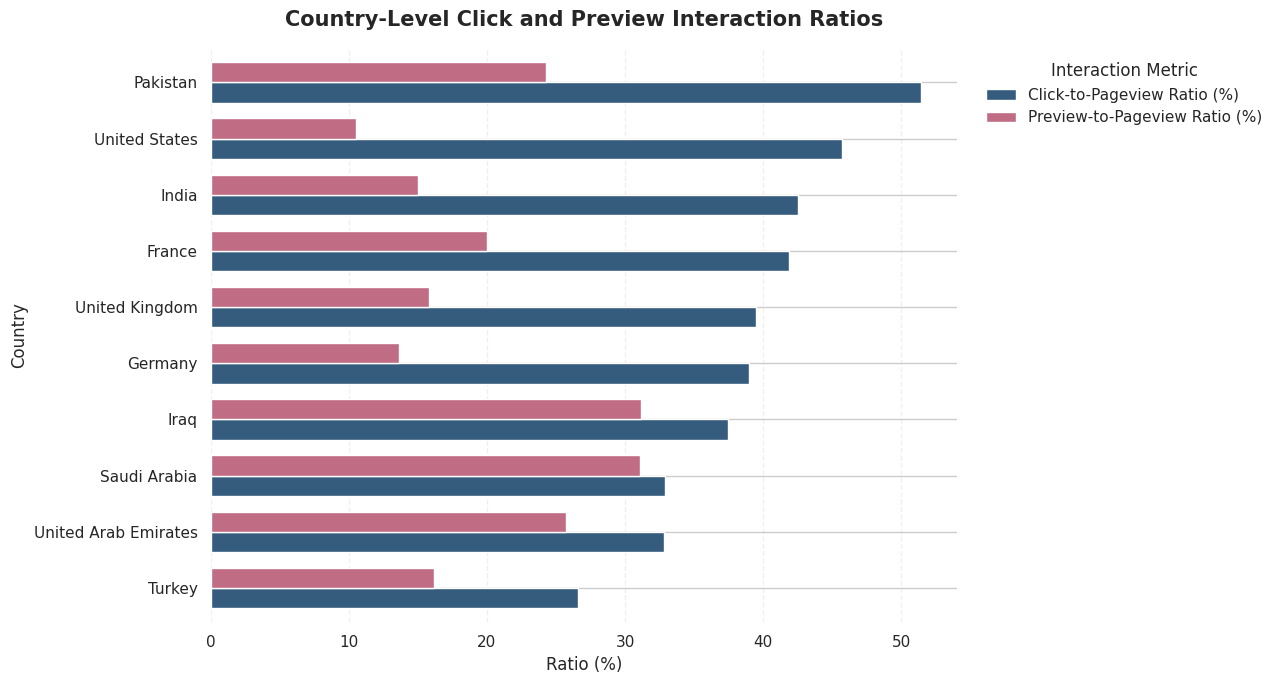

In [30]:
country_ratios = country_interaction[
    ['Click-to-Pageview Ratio (%)',
     'Preview-to-Pageview Ratio (%)']
].sort_values('Click-to-Pageview Ratio (%)')

fig, ax = plt.subplots(figsize=(13, 7))

country_ratios.plot(
    kind='barh',
    ax=ax,
    width=0.72,
    color=['#355C7D', '#C06C84']
)

ax.set_title(
    'Country-Level Click and Preview Interaction Ratios',
    fontsize=15,
    fontweight='bold',
    pad=16
)

ax.set_xlabel('Ratio (%)')
ax.set_ylabel('Country')

ax.legend(
    title='Interaction Metric',
    loc='upper left',
    bbox_to_anchor=(1.02, 1),
    frameon=False
)

ax.grid(axis='x', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()

## Country-Level Event Pattern Heatmap

### Objective
To visualize the distribution of recorded event categories across the ten leading countries.

### Analytical Approach
A country-by-event matrix is created using recorded event counts. A heatmap is used to identify differences in event volume across geographical markets and event categories.

### Analytical Focus
- Compare event volumes across countries.
- Identify countries with relatively higher or lower activity in each event category.
- Examine the overall distribution of Pageviews, Clicks, and Previews.

**Note:** The heatmap represents aggregated event counts, not unique visitors or session-level engagement.

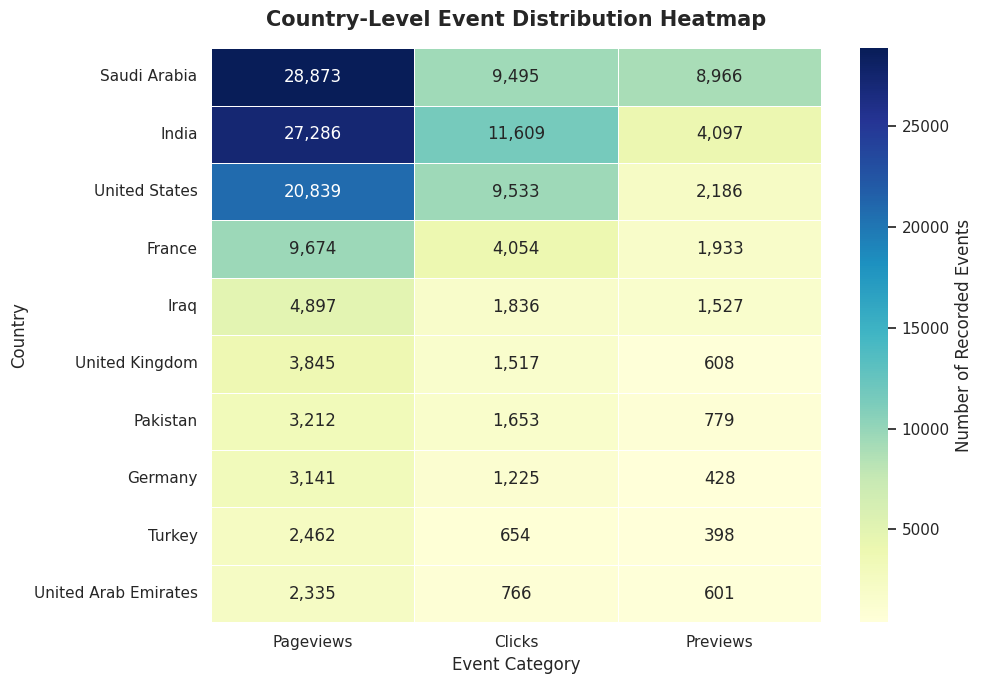

In [31]:
country_event_matrix = country_event_data[
    ['Pageviews', 'Clicks', 'Previews']
].sort_values('Pageviews', ascending=False)

plt.figure(figsize=(10, 7))

sns.heatmap(
    country_event_matrix,
    annot=True,
    fmt=',.0f',
    cmap='YlGnBu',
    linewidths=0.5,
    cbar_kws={'label': 'Number of Recorded Events'}
)

plt.title(
    'Country-Level Event Distribution Heatmap',
    fontsize=15,
    fontweight='bold',
    pad=16
)

plt.xlabel('Event Category')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

### Key Findings and Interpretation

1. Saudi Arabia recorded the highest Pageviews (28,873) and Previews (8,966) among the ten countries.
2. India recorded the highest Click count (11,609), despite ranking second in total event volume.
3. The United States ranked third in Pageviews (20,839) and Clicks (9,533).
4. Saudi Arabia showed comparatively high activity across all three event categories.
5. Pakistan recorded fewer total events than several other countries but demonstrated relatively high click activity compared with its Pageview count.
6. Pageviews were the largest event category across all ten countries, showing that browsing-related events contributed the highest recorded volume.

**Conclusion:** The heatmap highlights geographical differences in recorded event activity. Saudi Arabia and India were the leading markets by overall volume, while India led in click activity.

**Limitation:** The visualization uses absolute event counts. Differences in country activity should not be interpreted as differences in unique visitors or individual engagement because user and session identifiers are unavailable.

## City-Level Event Engagement Analysis

### Objective
To examine recorded event activity across the ten cities with the highest traffic volume.

### Analytical Approach
The top ten cities are identified based on total recorded events. Pageviews, Clicks, and Previews are grouped by city and compared through a stacked horizontal bar chart.

### Analytical Focus
- Identify cities with the highest recorded event activity.
- Compare the distribution of Pageviews, Clicks, and Previews.
- Examine differences in event patterns across leading cities.

**Note:** The analysis represents recorded event counts, not unique visitors or city-level conversion rates.

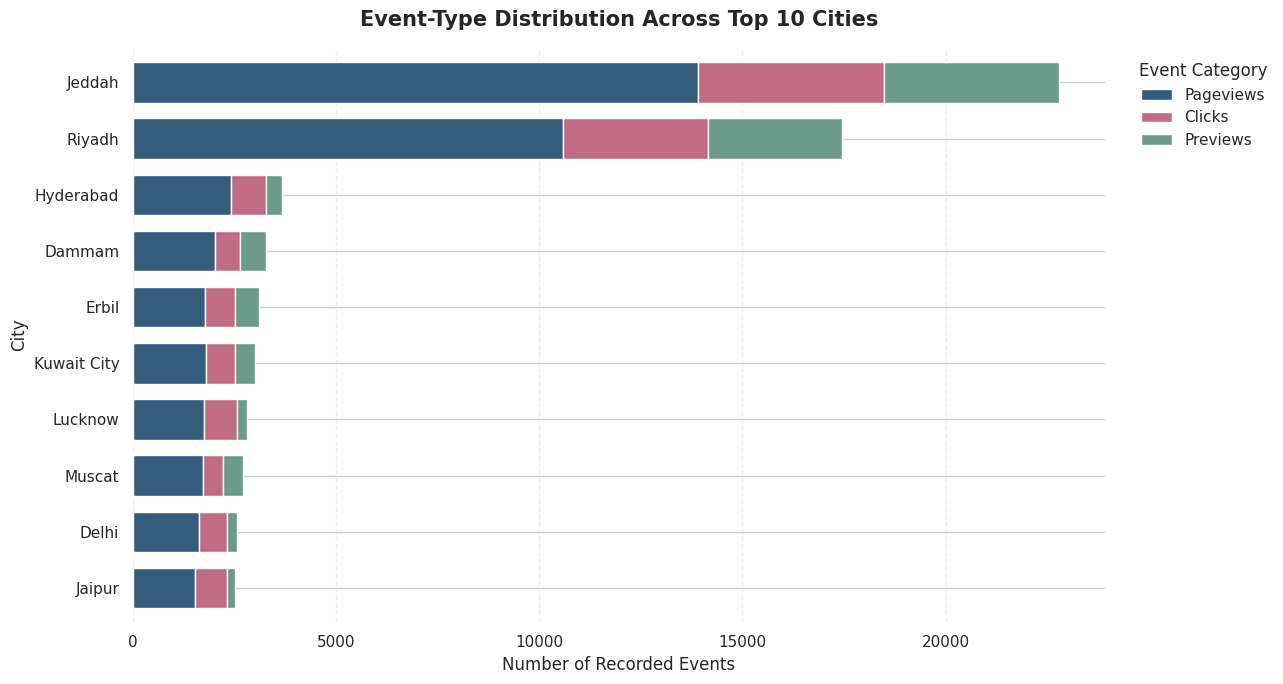

,Pageviews,Clicks,Previews,Total Events
city,,,,
Jaipur,1549,766,216,2531
Delhi,1638,686,243,2567
Muscat,1722,499,496,2717
Lucknow,1755,823,230,2808
Kuwait City,1806,707,497,3010
Erbil,1785,734,586,3105
Dammam,2031,617,628,3276
Hyderabad,2416,863,403,3682
Riyadh,10579,3572,3303,17454


In [32]:
top_10_cities = (
    df_clean[df_clean['city'] != 'Unknown']['city']
    .value_counts()
    .head(10)
    .index
)

city_event_data = (
    df_clean[df_clean['city'].isin(top_10_cities)]
    .groupby(['city', 'event'])
    .size()
    .unstack(fill_value=0)
)

city_event_data = city_event_data.reindex(
    columns=['pageview', 'click', 'preview'],
    fill_value=0
)

city_event_data.columns = ['Pageviews', 'Clicks', 'Previews']

city_event_data['Total Events'] = city_event_data.sum(axis=1)

city_event_data = city_event_data.sort_values(
    'Total Events',
    ascending=True
)

fig, ax = plt.subplots(figsize=(13, 7))

city_event_data[
    ['Pageviews', 'Clicks', 'Previews']
].plot(
    kind='barh',
    stacked=True,
    ax=ax,
    width=0.72,
    color=['#355C7D', '#C06C84', '#6C9A8B']
)

ax.set_title(
    'Event-Type Distribution Across Top 10 Cities',
    fontsize=15,
    fontweight='bold',
    pad=16
)

ax.set_xlabel('Number of Recorded Events')
ax.set_ylabel('City')

ax.legend(
    title='Event Category',
    loc='upper left',
    bbox_to_anchor=(1.02, 1),
    frameon=False
)

ax.grid(axis='x', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()

display(city_event_data)

### Key Findings and Interpretation

1. Jeddah recorded the highest total event volume among the ten cities, with 22,791 events, followed by Riyadh with 17,454 events.
2. Jeddah led across all three event categories, recording 13,898 Pageviews, 4,573 Clicks, and 4,320 Previews.
3. Hyderabad ranked third in total recorded activity, with 3,682 events.
4. Among the remaining cities, Dammam recorded the highest Preview count at 628, while Lucknow recorded the highest Click count at 823.
5. Jeddah and Riyadh contributed substantially higher event volumes than the other cities in the comparison.
6. Pageviews remained the largest event category across all ten cities.

**Conclusion:** The city-level analysis highlights Jeddah and Riyadh as the leading locations for recorded event activity. The remaining cities contributed comparatively smaller event volumes.

**Limitation:** These figures represent recorded events, not unique visitors. The dataset does not contain user or session identifiers to establish individual engagement or city-level conversion rates.

In [33]:
city_interaction = city_event_data[
    ['Pageviews', 'Clicks', 'Previews']
].copy()

city_interaction['Click-to-Pageview Ratio (%)'] = (
    city_interaction['Clicks'] /
    city_interaction['Pageviews'] * 100
)

city_interaction['Preview-to-Pageview Ratio (%)'] = (
    city_interaction['Previews'] /
    city_interaction['Pageviews'] * 100
)

city_interaction = city_interaction.sort_values(
    'Click-to-Pageview Ratio (%)',
    ascending=False
)

display(city_interaction.round(2))

,Pageviews,Clicks,Previews,Click-to-Pageview Ratio (%),Preview-to-Pageview Ratio (%)
city,,,,,
Jaipur,1549,766,216,49.45,13.94
Lucknow,1755,823,230,46.89,13.11
Delhi,1638,686,243,41.88,14.84
Erbil,1785,734,586,41.12,32.83
Kuwait City,1806,707,497,39.15,27.52
Hyderabad,2416,863,403,35.72,16.68
Riyadh,10579,3572,3303,33.77,31.22
Jeddah,13898,4573,4320,32.90,31.08
Dammam,2031,617,628,30.38,30.92


### Key Findings and Interpretation

1. Jaipur recorded the highest Click-to-Pageview Ratio at 49.45%, followed by Lucknow at 46.89%.
2. Erbil recorded the highest Preview-to-Pageview Ratio at 32.83%, indicating the highest relative preview-event volume among the ten cities.
3. Riyadh and Jeddah also recorded relatively high Preview-to-Pageview Ratios of 31.22% and 31.08%, respectively.
4. Muscat recorded the lowest Click-to-Pageview Ratio at 28.98%.
5. Jaipur and Lucknow showed comparatively higher click activity relative to their Pageview counts, while Erbil, Riyadh, and Jeddah showed higher relative preview activity.
6. The results demonstrate that cities with higher total event volumes do not necessarily have the highest interaction ratios.

**Conclusion:** Jaipur led in relative click activity, whereas Erbil led in relative preview activity. These differences highlight variations in recorded event patterns across cities.

**Limitation:** These ratios are calculated from aggregated event counts. They do not represent unique-user engagement, actual conversion rates, or individual visitor behaviour.

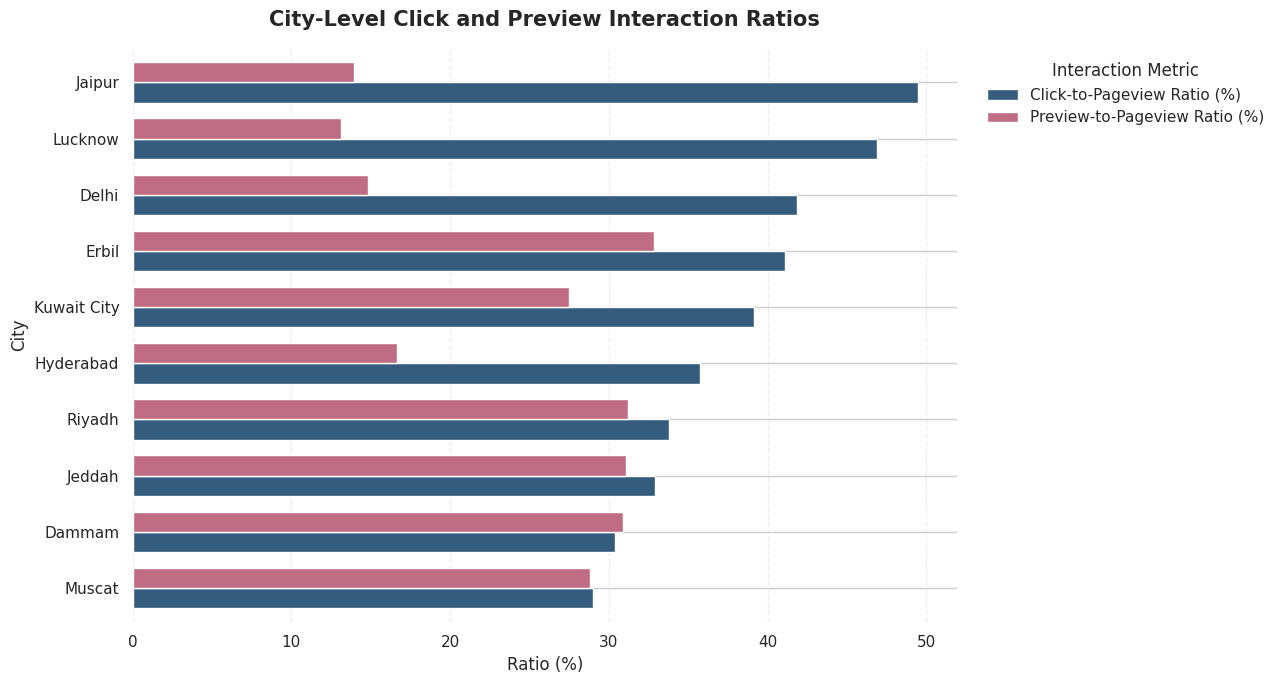

In [34]:
city_ratios = city_interaction[
    ['Click-to-Pageview Ratio (%)',
     'Preview-to-Pageview Ratio (%)']
].sort_values('Click-to-Pageview Ratio (%)')

fig, ax = plt.subplots(figsize=(13, 7))

city_ratios.plot(
    kind='barh',
    ax=ax,
    width=0.72,
    color=['#355C7D', '#C06C84']
)

ax.set_title(
    'City-Level Click and Preview Interaction Ratios',
    fontsize=15,
    fontweight='bold',
    pad=16
)

ax.set_xlabel('Ratio (%)')
ax.set_ylabel('City')

ax.legend(
    title='Interaction Metric',
    loc='upper left',
    bbox_to_anchor=(1.02, 1),
    frameon=False
)

ax.grid(axis='x', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()

## City-Level Event Distribution Heatmap

### Objective
To examine the distribution of recorded event categories across the ten leading cities.

### Analytical Approach
A city-by-event matrix is created using aggregated event counts. A heatmap is used to highlight differences in Pageviews, Clicks, and Previews across cities.

### Analytical Focus
- Compare event volumes across the leading cities.
- Identify cities with relatively higher activity in each event category.
- Examine geographical differences in recorded interaction patterns.

**Note:** The heatmap represents aggregated event counts, not unique visitors or session-level engagement.

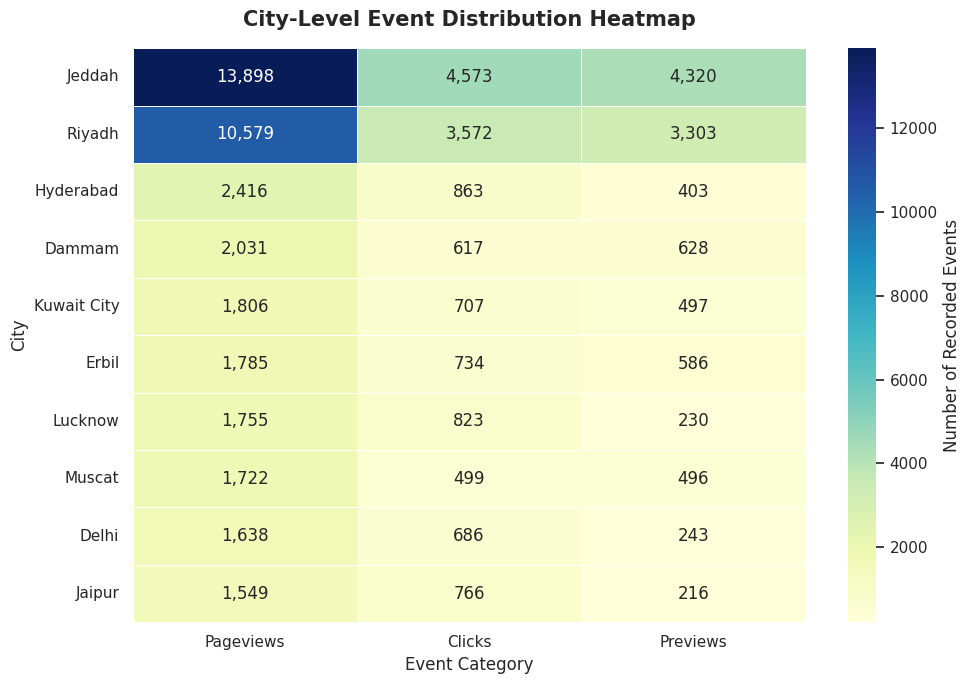

In [35]:
city_event_matrix = city_event_data[
    ['Pageviews', 'Clicks', 'Previews']
].sort_values('Pageviews', ascending=False)

plt.figure(figsize=(10, 7))

sns.heatmap(
    city_event_matrix,
    annot=True,
    fmt=',.0f',
    cmap='YlGnBu',
    linewidths=0.5,
    cbar_kws={'label': 'Number of Recorded Events'}
)

plt.title(
    'City-Level Event Distribution Heatmap',
    fontsize=15,
    fontweight='bold',
    pad=16
)

plt.xlabel('Event Category')
plt.ylabel('City')
plt.tight_layout()
plt.show()

### Key Findings and Interpretation

1. Jeddah recorded the highest activity across all three event categories, with 13,898 Pageviews, 4,573 Clicks, and 4,320 Previews.
2. Riyadh ranked second in all three categories, recording 10,579 Pageviews, 3,572 Clicks, and 3,303 Previews.
3. Hyderabad recorded the highest Pageview count among the remaining eight cities, with 2,416 events.
4. Lucknow recorded 823 Clicks, the highest click count among the cities outside Jeddah and Riyadh.
5. Dammam recorded 628 Previews, while Erbil recorded 586 Previews.
6. The heatmap highlights the substantial difference in recorded event volumes between Jeddah and Riyadh and the other cities.

**Conclusion:** Jeddah and Riyadh were the leading cities in recorded event activity. The remaining cities showed comparatively lower volumes, with differences in their Pageview, Click, and Preview patterns.

**Limitation:** These figures represent aggregated event counts rather than unique visitors. The dataset does not provide user or session identifiers to measure individual engagement or actual conversion rates.

## Cross-Dimensional Analysis

### Objective
To explore how recorded traffic events are distributed across geographical markets and content categories.

### Analytical Approach
Country and artist dimensions are combined to examine the distribution of recorded events. This analysis helps identify which artists contribute to event activity in the leading geographical markets.

### Analytical Focus
- Compare artist-level event activity across leading countries.
- Identify prominent artist and country combinations.
- Explore geographical differences in content-related event patterns.

**Note:** The analysis is based on aggregated event counts and does not identify individual users, sessions, or listening behaviour.

In [36]:
top_countries = (
    df_clean[df_clean['country'] != 'Unknown']['country']
    .value_counts()
    .head(5)
    .index
)

top_artists_cross = (
    df_clean[df_clean['artist'] != 'Unknown']['artist']
    .value_counts()
    .head(5)
    .index
)

country_artist_matrix = pd.crosstab(
    df_clean[
        df_clean['country'].isin(top_countries) &
        df_clean['artist'].isin(top_artists_cross)
    ]['country'],
    df_clean[
        df_clean['country'].isin(top_countries) &
        df_clean['artist'].isin(top_artists_cross)
    ]['artist']
)

country_artist_matrix

artist,Anne-Marie,"DMNDS, Strange Fruits Music, Fallen Roses, Lujavo, Nito-Onna","Surf Mesa, Emilee",Tesher,Tundra Beats
country,,,,,
France,436,647,399,2183,733
India,2770,566,2115,8469,2549
Iraq,745,181,277,3405,346
Saudi Arabia,2690,1241,2151,13080,2218
United States,324,378,371,942,700


### Key Findings and Interpretation

1. Tesher recorded the highest event count among the five selected artists in all five leading countries.
2. Saudi Arabia recorded the highest Tesher-related event count at 13,080, followed by India at 8,469.
3. India showed a comparatively broader distribution of activity across the selected artists, including 2,770 events for Anne-Marie and 2,549 for Tundra Beats.
4. In France, Tesher recorded 2,183 events, substantially higher than the other selected artists.
5. The United States recorded lower event counts across the selected artists compared with the other four countries.
6. The results indicate that content-related event volumes vary across geographical markets, with Tesher consistently leading this selected comparison.

**Conclusion:** Tesher was the leading artist by recorded event count across all five selected countries. However, the distribution of other artists' event activity varied by country.

**Limitation:** This analysis includes only the five highest-volume countries and five highest-volume artists. It represents aggregated event counts, not unique listeners, user preferences, or country-specific conversion rates.

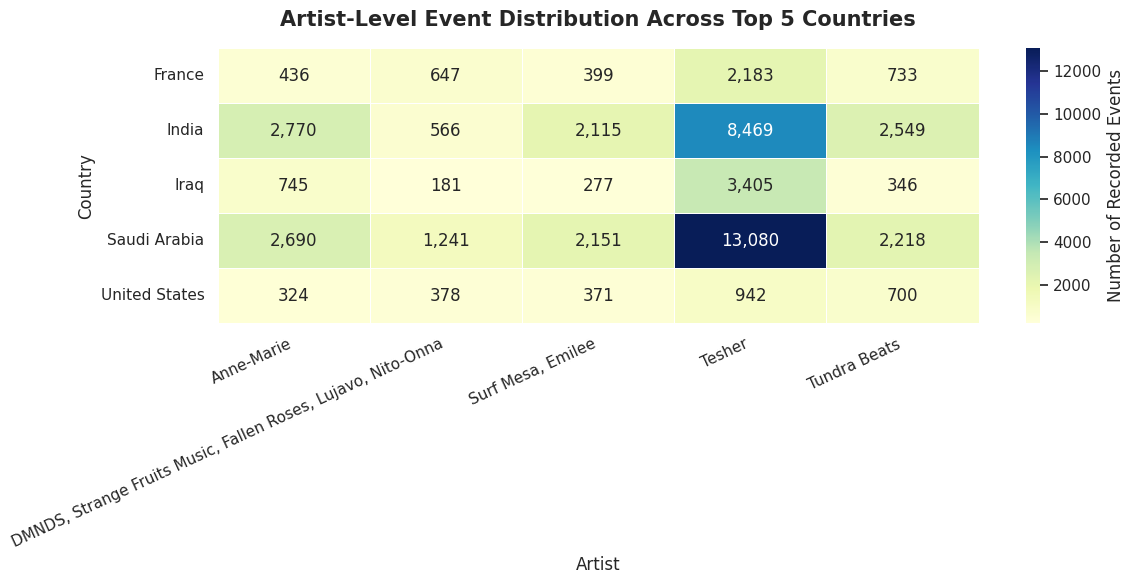

In [37]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    country_artist_matrix,
    annot=True,
    fmt=',.0f',
    cmap='YlGnBu',
    linewidths=0.5,
    cbar_kws={'label': 'Number of Recorded Events'}
)

plt.title(
    'Artist-Level Event Distribution Across Top 5 Countries',
    fontsize=15,
    fontweight='bold',
    pad=16
)

plt.xlabel('Artist')
plt.ylabel('Country')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

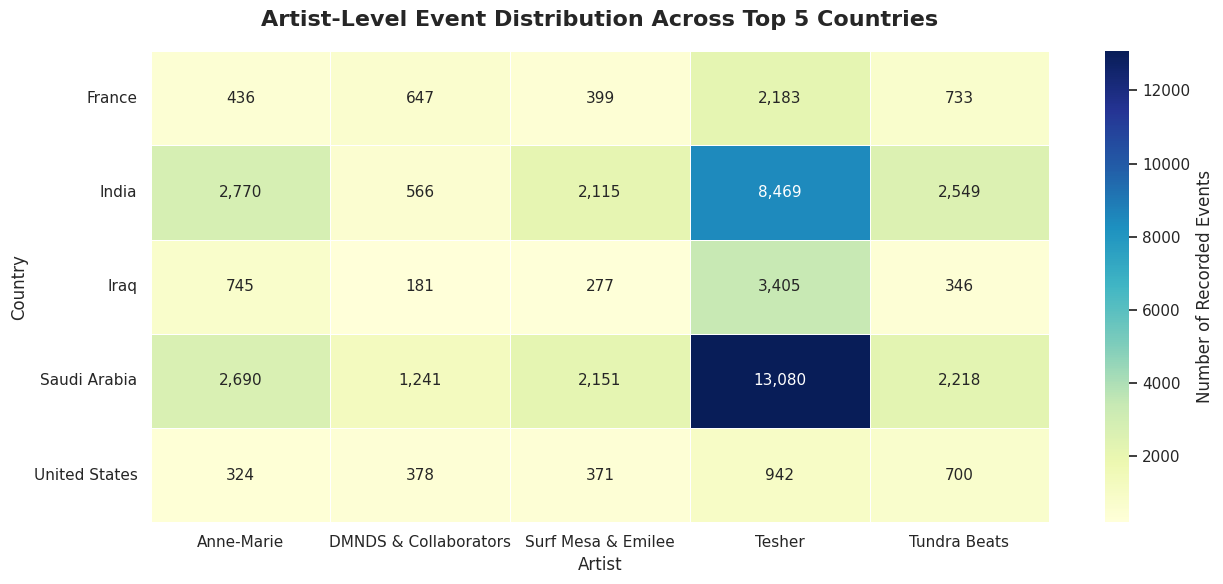

In [38]:
artist_labels = {
    'Anne-Marie': 'Anne-Marie',
    'DMNDS, Strange Fruits Music, Fallen Roses, Lujavo, Nito-Onna': 'DMNDS & Collaborators',
    'Surf Mesa, Emilee': 'Surf Mesa & Emilee',
    'Tesher': 'Tesher',
    'Tundra Beats': 'Tundra Beats'
}

heatmap_data = country_artist_matrix.rename(columns=artist_labels)

plt.figure(figsize=(13, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=',.0f',
    cmap='YlGnBu',
    linewidths=0.7,
    annot_kws={'size': 11},
    cbar_kws={'label': 'Number of Recorded Events'}
)

plt.title(
    'Artist-Level Event Distribution Across Top 5 Countries',
    fontsize=16,
    fontweight='bold',
    pad=18
)

plt.xlabel('Artist')
plt.ylabel('Country')
plt.xticks(rotation=0, ha='center')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

### Key Findings and Interpretation

1. Tesher recorded the highest event count among the five selected artists in all five leading countries.
2. Saudi Arabia recorded the highest Tesher-related event count at 13,080, followed by India at 8,469.
3. India showed comparatively higher activity for Anne-Marie, with 2,770 events, and Tundra Beats, with 2,549 events.
4. In France, Tesher recorded 2,183 events, considerably higher than the other selected artists.
5. The United States recorded lower event counts across the selected artists compared with the other four countries.
6. The results show that artist-level event volumes vary across geographical markets, although Tesher consistently leads this selected comparison.

**Conclusion:** Tesher was the leading artist by recorded event count across all five selected countries. The distribution of other artists' event activity varied by country.

**Limitation:** This analysis includes only the five highest-volume countries and five highest-volume artists. It represents aggregated event counts, not unique listeners, user preferences, or country-specific conversion rates.

## Day-of-Week Traffic Analysis

### Objective
To examine how recorded website event activity varies across different days of the week.

### Analytical Approach
The date column is used to derive the day of the week. Pageviews, Clicks, and Previews are then grouped by weekday and compared.

### Analytical Focus
- Identify the day with the highest recorded event activity.
- Compare event volumes across weekdays.
- Examine differences in Pageviews, Clicks, and Previews.

**Note:** The dataset covers only seven consecutive dates, from 19 August to 25 August 2021. Therefore, the results represent this specific observation period and should not be treated as a recurring weekly pattern.

In [39]:
df_clean['Day'] = df_clean['date'].dt.day_name()

weekday_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

weekday_events = (
    df_clean.groupby(['Day', 'event'])
    .size()
    .unstack(fill_value=0)
    .reindex(weekday_order)
    .dropna(how='all')
)

weekday_events = weekday_events.reindex(
    columns=['pageview', 'click', 'preview'],
    fill_value=0
)

weekday_events.columns = ['Pageviews', 'Clicks', 'Previews']

weekday_events['Total Events'] = weekday_events.sum(axis=1)

display(weekday_events)

,Pageviews,Clicks,Previews,Total Events
Day,,,,
Monday,18646,7315,3847,29808
Tuesday,18693,7301,3840,29834
Wednesday,19149,7476,3822,30447
Thursday,22366,9207,3788,35361
Friday,21382,8508,4222,34112
Saturday,21349,8071,4663,34083
Sunday,20430,7854,4349,32633


### Key Findings and Interpretation

1. Thursday recorded the highest total event volume, with 35,361 events, followed by Friday with 34,112 events.
2. Monday recorded the lowest total activity, with 29,808 events, while Tuesday recorded 29,834 events.
3. Thursday had the highest Pageview count (22,366) and Click count (9,207) during the observation period.
4. Saturday recorded the highest Preview count at 4,663, despite having fewer total events than Thursday and Friday.
5. Friday and Saturday showed similar total event volumes, with 34,112 and 34,083 events, respectively.
6. The distribution indicates that recorded event activity varied across the seven dates, with Thursday showing the highest overall volume.

**Conclusion:** Thursday was the most active day in the observed period, while Saturday led in Preview activity. These results describe the specific seven-day dataset and do not establish a recurring weekly traffic pattern.

**Limitation:** The dataset covers only one occurrence of each weekday. Therefore, the findings cannot establish consistent weekday or weekend behaviour.

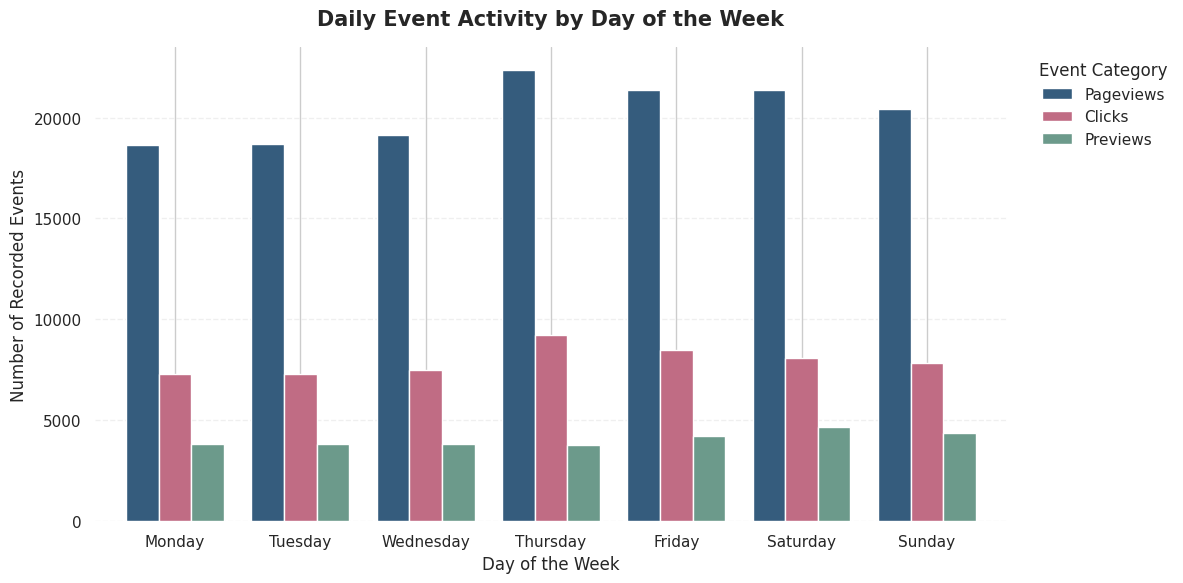

In [40]:
weekday_chart_data = weekday_events[
    ['Pageviews', 'Clicks', 'Previews']
]

ax = weekday_chart_data.plot(
    kind='bar',
    figsize=(12, 6),
    width=0.78,
    color=['#355C7D', '#C06C84', '#6C9A8B']
)

ax.set_title(
    'Daily Event Activity by Day of the Week',
    fontsize=15,
    fontweight='bold',
    pad=16
)

ax.set_xlabel('Day of the Week')
ax.set_ylabel('Number of Recorded Events')

ax.legend(
    title='Event Category',
    loc='upper left',
    bbox_to_anchor=(1.02, 1),
    frameon=False
)

ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
sns.despine(left=True, bottom=True)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Key Findings and Interpretation

1. Thursday recorded the highest total event volume, with 35,361 events.
2. Monday recorded the lowest total activity, with 29,808 events.
3. Thursday had the highest Pageview count (22,366) and Click count (9,207).
4. Saturday recorded the highest Preview count at 4,663.
5. Friday and Saturday showed similar total event volumes, with 34,112 and 34,083 events, respectively.
6. Pageviews remained the largest event category across all seven days.

**Conclusion:** Thursday showed the highest overall recorded activity, while Saturday led in Preview events. The distribution highlights variations in event volumes across the observation period.

**Limitation:** The dataset contains only one observation for each weekday. Therefore, these results cannot establish recurring weekly or seasonal traffic patterns.

## Content Engagement Analysis

### Album-Level Performance Analysis

### Objective
To identify the albums generating the highest recorded event activity in the dataset.

### Analytical Approach
Event records are grouped by album, and the ten albums with the highest recorded event counts are identified and ranked.

### Analytical Focus
- Identify the most frequently recorded albums.
- Compare event volumes across the leading albums.
- Understand how recorded activity is distributed among popular albums.

**Note:** Event counts represent recorded interactions and do not indicate unique listeners, streams, or revenue.

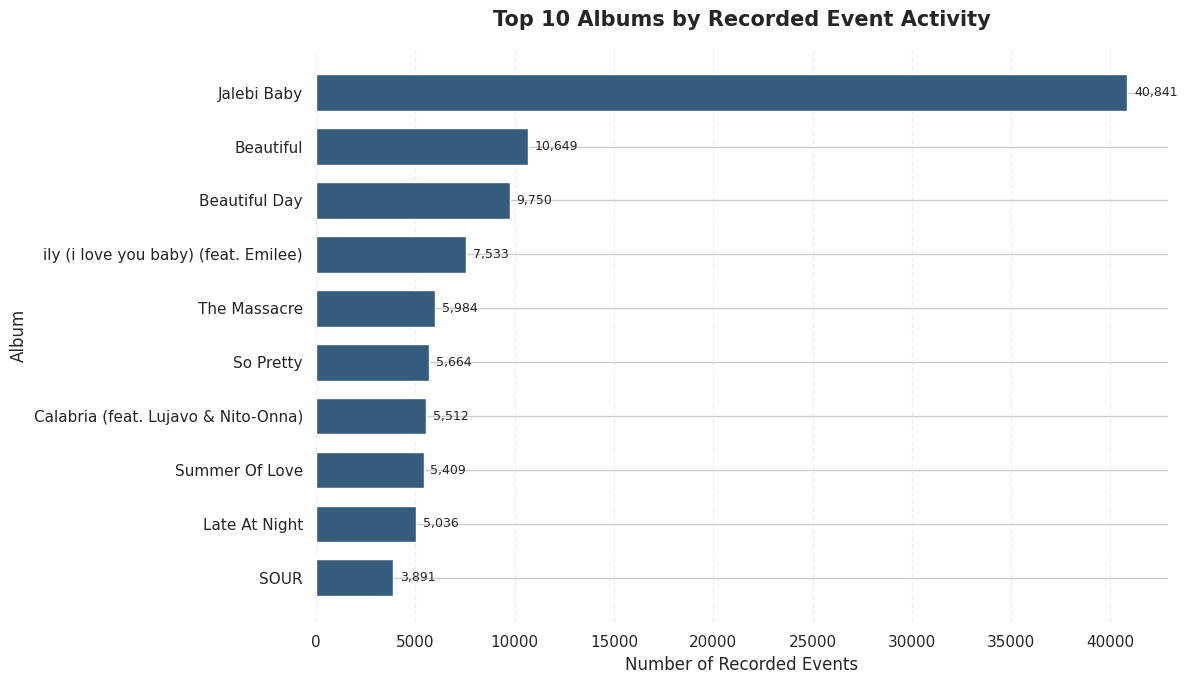

,Total Events
album,
Jalebi Baby,40841
Beautiful,10649
Beautiful Day,9750
ily (i love you baby) (feat. Emilee),7533
The Massacre,5984
So Pretty,5664
Calabria (feat. Lujavo & Nito-Onna),5512
Summer Of Love,5409
Late At Night,5036


In [41]:
album_event_counts = (
    df_clean[df_clean['album'] != 'Unknown']['album']
    .value_counts()
)

top_10_albums = album_event_counts.head(10)

album_chart = top_10_albums.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    album_chart.index,
    album_chart.values,
    color='#355C7D',
    height=0.68
)

ax.bar_label(
    bars,
    labels=[f'{value:,}' for value in album_chart.values],
    padding=5,
    fontsize=9
)

ax.set_title(
    'Top 10 Albums by Recorded Event Activity',
    fontsize=15,
    fontweight='bold',
    pad=16
)

ax.set_xlabel('Number of Recorded Events')
ax.set_ylabel('Album')

ax.grid(axis='x', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()

display(
    top_10_albums.rename('Total Events').to_frame()
)

### Key Findings and Interpretation

1. Jalebi Baby ranked first with 40,841 recorded events, showing a substantial lead over the other albums.
2. Beautiful ranked second with 10,649 events, followed by Beautiful Day with 9,750 events.
3. Jalebi Baby recorded approximately 3.83 times the event volume of Beautiful.
4. The fourth-ranked album, ily (i love you baby) (feat. Emilee), recorded 7,533 events.
5. The remaining albums in the top ten recorded between 3,891 and 5,984 events.
6. The distribution shows that recorded activity was concentrated around a small number of leading albums.

**Conclusion:** Jalebi Baby was the strongest album in terms of recorded event volume during the observation period, followed by Beautiful and Beautiful Day.

**Limitation:** These figures represent aggregated event records and do not indicate unique listeners, actual music streams, revenue, or user preferences.

### Track-Level Performance Analysis

### Objective
To identify the tracks generating the highest recorded event activity.

### Analytical Approach
Event records are grouped by track, and the ten tracks with the highest recorded event counts are identified and ranked.

### Analytical Focus
- Identify the most frequently recorded tracks.
- Compare event volumes across leading tracks.
- Examine the concentration of recorded activity among popular tracks.

**Note:** Track-level event counts represent recorded interactions, not unique listeners or confirmed music streams.

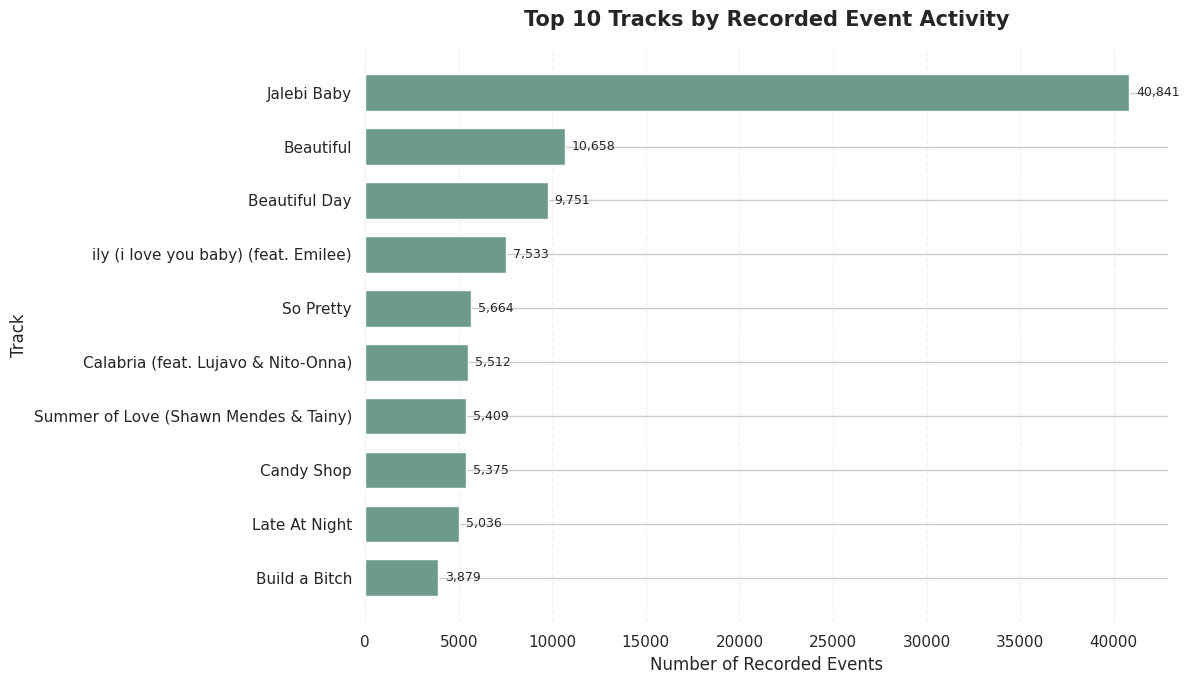

,Total Events
track,
Jalebi Baby,40841
Beautiful,10658
Beautiful Day,9751
ily (i love you baby) (feat. Emilee),7533
So Pretty,5664
Calabria (feat. Lujavo & Nito-Onna),5512
Summer of Love (Shawn Mendes & Tainy),5409
Candy Shop,5375
Late At Night,5036


In [42]:
track_event_counts = (
    df_clean[df_clean['track'] != 'Unknown']['track']
    .value_counts()
)

top_10_tracks = track_event_counts.head(10)

track_chart = top_10_tracks.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    track_chart.index,
    track_chart.values,
    color='#6C9A8B',
    height=0.68
)

ax.bar_label(
    bars,
    labels=[f'{value:,}' for value in track_chart.values],
    padding=5,
    fontsize=9
)

ax.set_title(
    'Top 10 Tracks by Recorded Event Activity',
    fontsize=15,
    fontweight='bold',
    pad=16
)

ax.set_xlabel('Number of Recorded Events')
ax.set_ylabel('Track')

ax.grid(axis='x', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()

display(
    top_10_tracks.rename('Total Events').to_frame()
)

### Key Findings and Interpretation

1. Jalebi Baby ranked first with 40,841 recorded events, making it the most active track in the dataset.
2. Beautiful ranked second with 10,658 events, followed by Beautiful Day with 9,751 events.
3. Jalebi Baby recorded approximately 3.83 times the event volume of Beautiful.
4. The track ily (i love you baby) (feat. Emilee) recorded 7,533 events and ranked fourth.
5. Candy Shop and Build a Bitch also appeared among the ten leading tracks, recording 5,375 and 3,879 events, respectively.
6. The results indicate that recorded activity was concentrated around a few leading tracks.

**Conclusion:** Jalebi Baby was the leading track by recorded event volume during the observation period, followed by Beautiful and Beautiful Day.

**Limitation:** These figures represent aggregated event records and do not establish unique listeners, confirmed music streams, revenue, or individual listening preferences.

In [44]:
content_comparison = pd.DataFrame({
    'Top 5 Albums': album_event_counts.head(5),
    'Top 5 Tracks': track_event_counts.head(5)
})

display(
    content_comparison.style
    .format('{:,.0f}', na_rep='—')
    .set_caption('Comparison of Top 5 Albums and Tracks')
)

,Top 5 Albums,Top 5 Tracks
Beautiful,"10,649","10,658"
Beautiful Day,"9,750","9,751"
Jalebi Baby,"40,841","40,841"
So Pretty,—,"5,664"
The Massacre,"5,984",—
ily (i love you baby) (feat. Emilee),"7,533","7,533"


### Key Findings and Interpretation

1. Jalebi Baby recorded 40,841 events at both album and track levels.
2. Beautiful showed a difference of 9 events between its album count (10,649) and track count (10,658).
3. Beautiful Day showed a difference of only 1 event between its album and track counts.
4. The album The Massacre appeared in the top five albums, whereas So Pretty appeared in the top five tracks.
5. The comparison highlights similarities in the leading album and track names, along with differences in their rankings.

**Conclusion:** Jalebi Baby, Beautiful, Beautiful Day, and ily (i love you baby) appeared among the leading entries at both content levels. The comparison provides a useful view of recorded activity across album and track categories.

**Limitation:** Album and track counts are calculated independently. Similar names and event counts do not establish a one-to-one relationship between album and track records.

## Aggregate Event Interaction Analysis

### Objective
To compare the volume of Pageviews, Clicks, and Previews and examine their relative proportions in the recorded event data.

### Analytical Approach
The three event categories are aggregated to calculate their total counts and percentage shares. Click and Preview counts are also compared with Pageview counts using aggregate event ratios.

### Analytical Focus
- Compare the overall volume of each event category.
- Calculate the share of each event type in total recorded events.
- Examine Click-to-Pageview and Preview-to-Pageview ratios.
- Identify differences in the distribution of recorded interactions.

**Note:** This is an aggregate event comparison, not a user-level conversion funnel. The dataset does not contain the identifiers required to track individual visitors through a sequence of actions.

In [45]:
event_summary = (
    df_clean['event']
    .value_counts()
    .reindex(['pageview', 'click', 'preview'], fill_value=0)
    .rename_axis('Event Category')
    .reset_index(name='Total Events')
)

total_events = event_summary['Total Events'].sum()

event_summary['Share of Total (%)'] = (
    event_summary['Total Events'] / total_events * 100
)

event_counts = df_clean['event'].value_counts()

pageviews = event_counts.get('pageview', 0)
clicks = event_counts.get('click', 0)
previews = event_counts.get('preview', 0)

event_ratios = pd.DataFrame({
    'Metric': [
        'Click-to-Pageview Ratio',
        'Preview-to-Pageview Ratio'
    ],
    'Ratio (%)': [
        clicks / pageviews * 100,
        previews / pageviews * 100
    ]
})

display(event_summary)
display(event_ratios)

,Event Category,Total Events,Share of Total (%)
0,pageview,142015,62.761294
1,click,55732,24.629880
2,preview,28531,12.608826


,Metric,Ratio (%)
0,Click-to-Pageview Ratio,39.243742
1,Preview-to-Pageview Ratio,20.090131


### Key Findings and Interpretation

1. Pageviews accounted for the largest share of recorded activity, with 142,015 events representing 62.76% of the total.
2. Clicks contributed 55,732 events, accounting for 24.63% of all recorded events.
3. Previews represented 28,531 events, equivalent to 12.61% of total activity.
4. The aggregate Click-to-Pageview Ratio was 39.24%.
5. The aggregate Preview-to-Pageview Ratio was 20.09%.
6. Pageviews were approximately 2.55 times the number of Clicks and 4.98 times the number of Previews.

**Conclusion:** Pageviews dominated the recorded event distribution, followed by Clicks and Previews. The aggregate ratios provide an additional perspective on the relative volumes of these event categories.

**Limitation:** These ratios are calculated using total event counts. They do not represent unique-user conversion rates or indicate how many individual visitors progressed from one event to another.

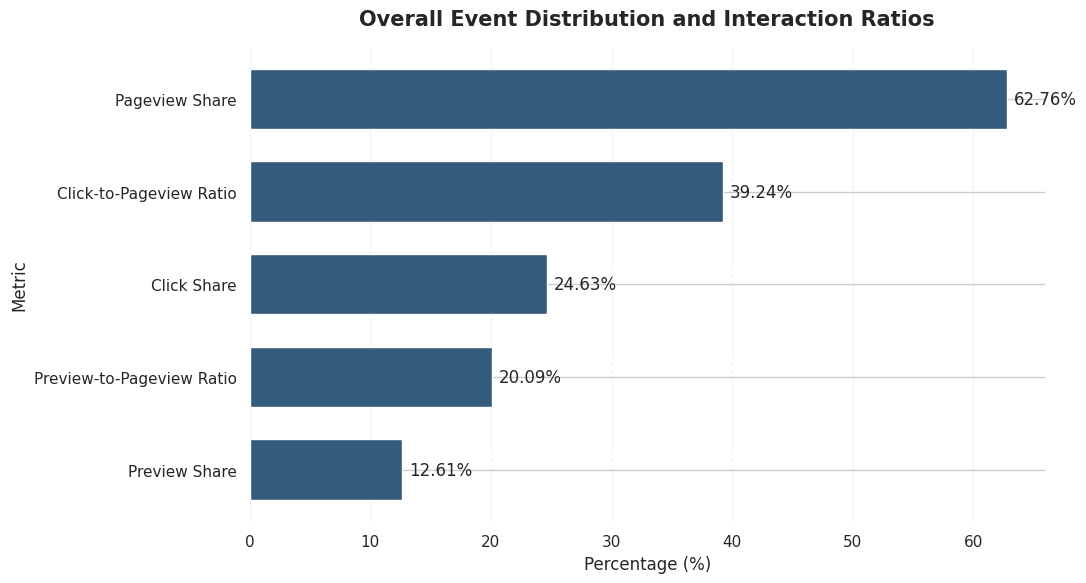

In [46]:
event_visual_data = pd.DataFrame({
    'Metric': [
        'Pageview Share',
        'Click Share',
        'Preview Share',
        'Click-to-Pageview Ratio',
        'Preview-to-Pageview Ratio'
    ],
    'Percentage': [
        62.761294,
        24.629880,
        12.608826,
        39.243742,
        20.090131
    ]
})

event_visual_data = event_visual_data.sort_values(
    'Percentage', ascending=True
)

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    event_visual_data['Metric'],
    event_visual_data['Percentage'],
    color='#355C7D',
    height=0.65
)

ax.bar_label(
    bars,
    labels=[f'{v:.2f}%' for v in event_visual_data['Percentage']],
    padding=5
)

ax.set_title(
    'Overall Event Distribution and Interaction Ratios',
    fontsize=15,
    fontweight='bold',
    pad=16
)

ax.set_xlabel('Percentage (%)')
ax.set_ylabel('Metric')
ax.grid(axis='x', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()

## Business Insights and Strategic Recommendations

### Key Business Insights

1. **Dominant Event Category:** Pageviews account for 62.76% of all recorded events, making them the largest category of activity.
2. **Geographical Concentration:** Saudi Arabia and India are the leading countries by recorded event volume.
3. **Leading Content:** Tesher and the track Jalebi Baby show the highest recorded event activity among the analysed artists and tracks.
4. **City-Level Performance:** Jeddah and Riyadh contribute the highest event volumes among the ten leading cities.
5. **Daily Activity Variation:** Thursday recorded the highest total event activity during the seven-day observation period.
6. **Differences in Interaction Patterns:** Jaipur recorded the highest Click-to-Pageview Ratio among the selected cities, while Erbil recorded the highest Preview-to-Pageview Ratio.
7. **Content and Market Differences:** Artist-level event counts vary across geographical markets, although Tesher leads the selected artist comparison in all five leading countries.

### Strategic Recommendations

1. **Strengthen Leading Markets:** Examine the traffic patterns in Saudi Arabia and India to identify opportunities for improving content reach and engagement.
2. **Promote Popular Content:** Consider featuring high-activity artists, albums, and tracks to encourage further content discovery.
3. **Study City-Level Differences:** Investigate the different event patterns observed in Jaipur, Lucknow, Erbil, Jeddah, and Riyadh before planning location-specific engagement initiatives.
4. **Improve Event Tracking:** Introduce unique user IDs, session IDs, timestamps, page URLs, and referral-source fields to enable accurate measurement of sessions, bounce rates, and user journeys.
5. **Monitor Performance Over Longer Periods:** Analyse traffic across several weeks and months to identify recurring patterns and seasonal variations.
6. **Build a Performance Dashboard:** Track Pageviews, Clicks, Previews, geographical activity, and content performance through a regularly updated dashboard.

**Overall Recommendation:** Future digital performance analysis should combine event-volume monitoring with reliable user-level and session-level tracking. This would enable more accurate engagement measurement and stronger data-driven decisions.

## Limitations of the Analysis

The analysis provides useful insights into recorded website traffic events. However, certain limitations should be considered while interpreting the results.

1. **Limited Observation Period:** The dataset covers only seven days, from 19 August to 25 August 2021. The results may not represent long-term traffic patterns.
2. **No Unique User Identifier:** The dataset does not contain a user ID, so unique visitors cannot be identified.
3. **No Session Information:** Session IDs and session timestamps are unavailable. Therefore, actual sessions, bounce rates, and average session duration cannot be calculated.
4. **No User Journey Tracking:** The available records do not establish the sequence of actions performed by individual visitors.
5. **No Landing or Exit Page Information:** Page URLs and page-level navigation details are not available.
6. **No Referral Source Data:** The dataset does not identify the channels or sources from which visitors arrived.
7. **Repeated Event Records:** The dataset contains exact duplicate rows. These were retained because repeated events may represent legitimate activity, and the available fields do not provide sufficient evidence to distinguish them from duplicate logging.
8. **Limited Conversion Measurement:** Aggregate event ratios cannot be interpreted as actual user-level conversion rates.
9. **Historical Dataset:** The records belong to August 2021 and should not be treated as a representation of current website traffic.

**Overall:** The findings should be interpreted as patterns in recorded event activity rather than complete measurements of website users, sessions, or conversions.

## Conclusion

The Website Traffic & User Engagement Analysis examined 226,278 recorded event records across seven days, covering 211 countries, 11,993 cities, and multiple artists, albums, tracks, and link identifiers.

The analysis identified Pageviews as the largest event category, accounting for 62.76% of total recorded activity, followed by Clicks at 24.63% and Previews at 12.61%.

Geographical analysis highlighted Saudi Arabia and India as the leading countries by event volume, while Jeddah and Riyadh were the most active cities among the leading locations.

Content analysis identified Tesher and Jalebi Baby as the leading artist and track, respectively, based on recorded event counts. Daily analysis showed that Thursday had the highest total event activity during the observation period.

The project also demonstrated how data cleaning, exploratory data analysis, statistical summaries, and visualizations can transform raw event records into meaningful business insights.

Although the available dataset did not support session-level or unique-user engagement metrics, the analysis established a useful foundation for understanding recorded traffic patterns and identifying opportunities for further investigation.

Overall, this project strengthened practical skills in Python, Pandas, NumPy, Matplotlib, Seaborn, data cleaning, exploratory analysis, visualization, and business interpretation.

## Project Summary

The Website Traffic & User Engagement Analysis project involved examining 226,278 recorded event records collected over a seven-day period.

The project followed a structured data analytics workflow:

1. **Data Collection:** Loaded the website traffic dataset into Google Colab.
2. **Data Understanding:** Examined dataset dimensions, columns, data types, and statistical summaries.
3. **Data Cleaning:** Converted dates into datetime format, investigated missing values and duplicate records, and handled missing categorical values.
4. **Exploratory Data Analysis:** Analysed event categories, daily activity, geographical distribution, and content performance.
5. **Data Visualization:** Created bar charts, line charts, grouped bar charts, stacked bar charts, and heatmaps.
6. **Cross-Dimensional Analysis:** Examined relationships between leading countries, artists, albums, tracks, and link identifiers.
7. **Business Interpretation:** Identified key patterns and developed strategic recommendations based on the available data.
8. **Reporting:** Documented findings, analytical limitations, and conclusions.

The project demonstrates the application of Python-based data analytics techniques to transform raw event data into structured insights that can support business understanding and further investigation.

## Tools and Technologies Used

| Tool / Technology | Purpose |
|---|---|
| Python | Data analysis and processing |
| Google Colab | Cloud-based notebook environment |
| Pandas | Data manipulation and analysis |
| NumPy | Numerical operations |
| Matplotlib | Data visualization |
| Seaborn | Statistical visualization and heatmaps |

### Key Analytical Techniques

- Data cleaning and preprocessing
- Missing-value analysis
- Duplicate-record investigation
- Descriptive statistics
- Exploratory Data Analysis (EDA)
- Grouping and aggregation
- Comparative and trend analysis
- Interaction ratio calculations
- Cross-dimensional analysis
- Business insight generation

## Project Deliverables

The following deliverables were prepared as part of this project:

1. **Cleaned Dataset:** A processed version of the original website traffic dataset with standardized date values and handled missing categorical entries.
2. **Jupyter Notebook:** A structured Google Colab notebook containing data loading, preprocessing, exploratory analysis, calculations, and visualizations.
3. **Exploratory Visualizations:** Charts and heatmaps illustrating event distribution, daily activity, geographical patterns, and content performance.
4. **Business Insights:** Key observations derived from the analysed event records.
5. **Strategic Recommendations:** Practical suggestions based on geographical and content-level activity patterns.
6. **Project Documentation:** Detailed explanation of the methodology, findings, limitations, and conclusion.

### Final Outcome

The project provides a structured analysis of recorded website traffic events and demonstrates how data analytics techniques can support evidence-based business interpretation.

## Executive Dashboard

### Website Traffic & User Engagement Overview

This dashboard presents a consolidated view of the key findings from the website traffic event analysis. It highlights overall event activity, geographical contribution, and leading content categories.

The dashboard is designed to provide a quick overview of the dataset and support evidence-based interpretation of recorded traffic patterns.

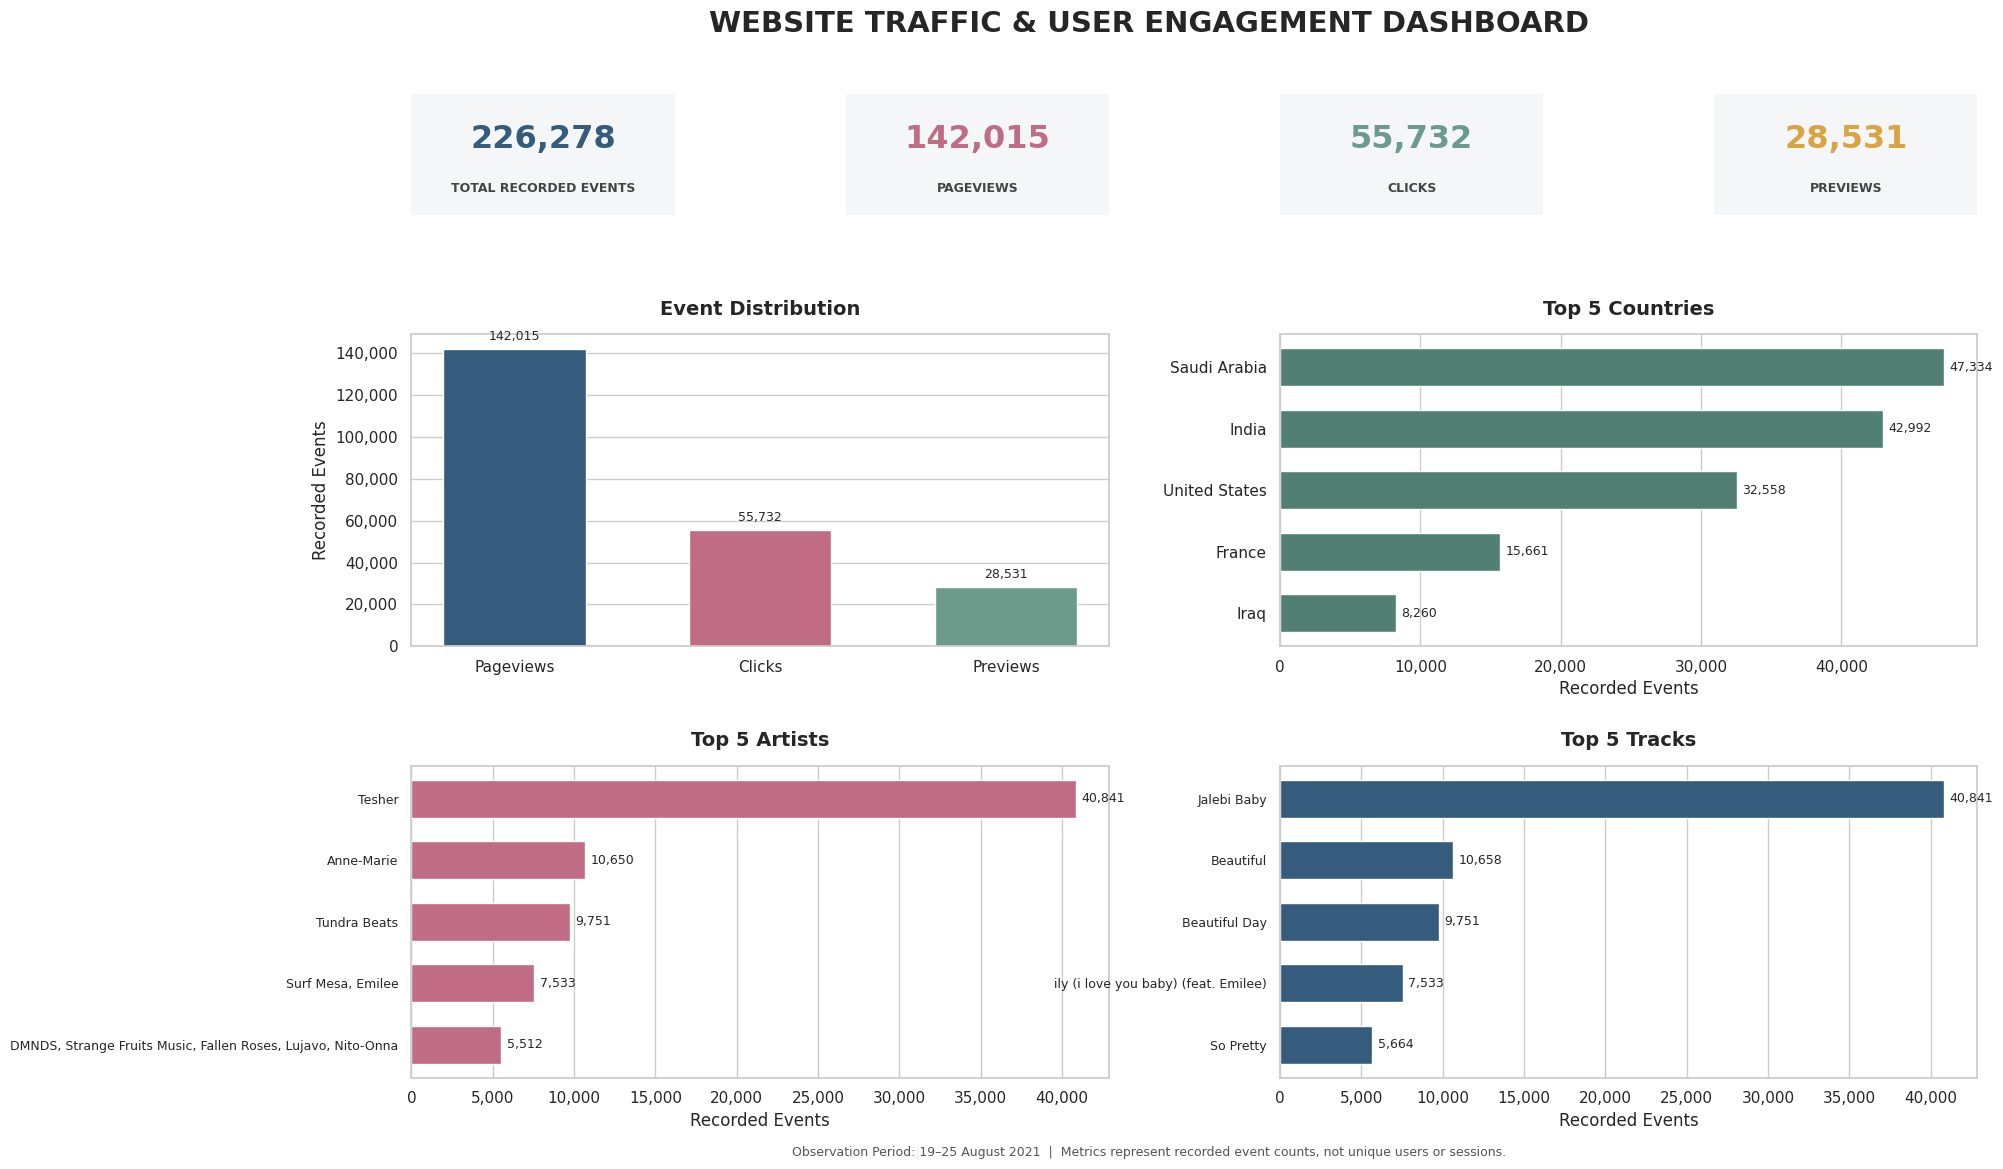

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# -----------------------------
# 1. Prepare dashboard metrics
# -----------------------------

total_records = len(df_clean)

event_counts = df_clean['event'].value_counts()

total_pageviews = event_counts.get('pageview', 0)
total_clicks = event_counts.get('click', 0)
total_previews = event_counts.get('preview', 0)

top_countries = (
    df_clean[df_clean['country'] != 'Unknown']['country']
    .value_counts()
    .head(5)
)

top_artists = (
    df_clean[df_clean['artist'] != 'Unknown']['artist']
    .value_counts()
    .head(5)
)

top_tracks = (
    df_clean[df_clean['track'] != 'Unknown']['track']
    .value_counts()
    .head(5)
)

# -----------------------------
# 2. Dashboard layout
# -----------------------------

sns.set_theme(style="whitegrid")

fig = plt.figure(figsize=(18, 12))

gs = fig.add_gridspec(
    3, 4,
    height_ratios=[0.85, 2.2, 2.2],
    hspace=0.48,
    wspace=0.65
)

fig.suptitle(
    'WEBSITE TRAFFIC & USER ENGAGEMENT DASHBOARD',
    fontsize=21,
    fontweight='bold',
    y=0.98
)

# -----------------------------
# 3. KPI Cards
# -----------------------------

kpis = [
    ("TOTAL RECORDED EVENTS", total_records, "#355C7D"),
    ("PAGEVIEWS", total_pageviews, "#C06C84"),
    ("CLICKS", total_clicks, "#6C9A8B"),
    ("PREVIEWS", total_previews, "#D9A441")
]

for i, (label, value, color) in enumerate(kpis):

    ax = fig.add_subplot(gs[0, i])
    ax.set_facecolor("#F4F6F8")

    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.set_xticks([])
    ax.set_yticks([])

    ax.text(
        0.5, 0.62,
        f"{value:,}",
        ha='center',
        va='center',
        fontsize=23,
        fontweight='bold',
        color=color
    )

    ax.text(
        0.5, 0.22,
        label,
        ha='center',
        va='center',
        fontsize=9,
        fontweight='bold',
        color="#444444"
    )

# -----------------------------
# 4. Event Distribution
# -----------------------------

ax1 = fig.add_subplot(gs[1, 0:2])

event_order = ['pageview', 'click', 'preview']
event_values = [event_counts.get(e, 0) for e in event_order]

bars = ax1.bar(
    ['Pageviews', 'Clicks', 'Previews'],
    event_values,
    color=['#355C7D', '#C06C84', '#6C9A8B'],
    width=0.58
)

ax1.set_title("Event Distribution", fontsize=14, fontweight='bold', pad=14)
ax1.set_ylabel("Recorded Events")
ax1.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{int(x):,}'))

ax1.bar_label(
    bars,
    labels=[f'{v:,}' for v in event_values],
    padding=4,
    fontsize=9
)

ax1.grid(axis='x', visible=False)
ax1.set_axisbelow(True)

# -----------------------------
# 5. Top 5 Countries
# -----------------------------

ax2 = fig.add_subplot(gs[1, 2:4])

countries = top_countries.sort_values()

bars = ax2.barh(
    countries.index,
    countries.values,
    color='#527F73',
    height=0.62
)

ax2.set_title("Top 5 Countries", fontsize=14, fontweight='bold', pad=14)
ax2.set_xlabel("Recorded Events")
ax2.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{int(x):,}'))

ax2.bar_label(
    bars,
    labels=[f'{v:,}' for v in countries.values],
    padding=4,
    fontsize=9
)

ax2.grid(axis='y', visible=False)
ax2.set_axisbelow(True)

# -----------------------------
# 6. Top 5 Artists
# -----------------------------

ax3 = fig.add_subplot(gs[2, 0:2])

artists = top_artists.sort_values()

bars = ax3.barh(
    artists.index,
    artists.values,
    color='#C06C84',
    height=0.62
)

ax3.set_title("Top 5 Artists", fontsize=14, fontweight='bold', pad=14)
ax3.set_xlabel("Recorded Events")
ax3.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{int(x):,}'))

ax3.tick_params(axis='y', labelsize=9)

ax3.bar_label(
    bars,
    labels=[f'{v:,}' for v in artists.values],
    padding=4,
    fontsize=9
)

ax3.grid(axis='y', visible=False)
ax3.set_axisbelow(True)

# -----------------------------
# 7. Top 5 Tracks
# -----------------------------

ax4 = fig.add_subplot(gs[2, 2:4])

tracks = top_tracks.sort_values()

bars = ax4.barh(
    tracks.index,
    tracks.values,
    color='#355C7D',
    height=0.62
)

ax4.set_title("Top 5 Tracks", fontsize=14, fontweight='bold', pad=14)
ax4.set_xlabel("Recorded Events")
ax4.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{int(x):,}'))

ax4.tick_params(axis='y', labelsize=9)

ax4.bar_label(
    bars,
    labels=[f'{v:,}' for v in tracks.values],
    padding=4,
    fontsize=9
)

ax4.grid(axis='y', visible=False)
ax4.set_axisbelow(True)

# -----------------------------
# 8. Final formatting
# -----------------------------

fig.text(
    0.5, 0.025,
    'Observation Period: 19–25 August 2021  |  Metrics represent recorded event counts, not unique users or sessions.',
    ha='center',
    fontsize=9,
    color='#555555'
)

plt.subplots_adjust(
    top=0.91,
    bottom=0.09,
    left=0.09,
    right=0.96
)

plt.show()